# MILESTONE 1 UTS TEXT MINING
**Topik:** Prediksi hasil penanganan pengaduan konsumen laporan kredit (CFPB) — kolom target `Company response to consumer`.

**Metode:** Classical Machine Learning (TF-IDF + fitur kategorikal, klasifikasi multikelas)·

**Struktur:** Pertemuan 1–7 → UTS.

**Mata Kuliah:** Pembelajaran Mesin | **Kelompok:** A12
1. Fauzan Ramadhan Harahap — NIM: [231110937]
2. Eka Satria — NIM: [231111582]
3. Mhd. Hatami — NIM: [231111710]





## 0. Setup & Konfigurasi
Sesuaikan bagian ini saja. Untuk data ±1 juta baris, `SAMPLE_N=300_000` sudah cukup untuk eksperimen; set `None` untuk memakai seluruh data (lebih lama).

In [ ]:
# [CELL 1] Import library & seed (reproducibility)
import os, re, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from scipy import stats
from scipy.stats import loguniform
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import OneHotEncoder, Normalizer, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.cluster import KMeans
from sklearn.feature_selection import SelectKBest, SelectPercentile, chi2
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             f1_score, recall_score, matthews_corrcoef, average_precision_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             make_scorer, silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Environment siap. RANDOM_STATE =", RANDOM_STATE, "| Colab:", IN_COLAB)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Environment siap. RANDOM_STATE = 42 | Colab: True
pandas 2.2.3 | scikit-learn 1.6.1


In [ ]:
# [CELL 2] KONFIGURASI — sesuaikan bagian ini saja
# Perkiraan kasar: dengan nilai default dan data ±1 juta baris, Run all memakan puluhan menit di Colab (belum diukur pada data Anda).
# Untuk uji cepat, kecilkan SAMPLE_N (mis. 50_000), CV_SAMPLE_N (mis. 20_000), dan N_ITER_TUNE (mis. 4).
DATA_PATH = "/content/drive/MyDrive/Dataset/complaints.csv"
TARGET_COL = "Company response to consumer"
NARRATIVE_CANDIDATES = ["Consumer complaint narrative", "consumer_complaint_narrative"]

TEXT_COLS = ["Product", "Sub-product", "Issue", "Sub-issue"]      # dibentuk menjadi teks
CAT_COLS = ["Company", "State", "Submitted via", "Tags"]          # fitur kategorikal (diketahui saat pengaduan masuk)
LEAKY_COLS = ["Timely response?", "Company public response"]      # baru diketahui setelah perusahaan merespons -> DIKELUARKAN
ID_COL, DATE_COL = "Complaint ID", "Date received"
EXCEL_ROW_LIMIT = 1_048_575      # baris data maksimum Excel (di luar header)

MIN_CLASS_COUNT = 50             # kelas dengan jumlah < ini dibuang
SAMPLE_N = 300_000               # ukuran data kerja (stratified). None = seluruh data
EXPLORE_N = 300_000              # sampel untuk eksplorasi informasi fitur (P2)
CV_SAMPLE_N = 60_000             # ukuran sampel untuk cross-validation (P5)
TUNE_SAMPLE_N = 60_000           # ukuran sampel untuk seleksi fitur dan tuning (P7)
N_ITER_TUNE = 12                 # jumlah kombinasi RandomizedSearchCV
CV_FOLDS = 5
TEST_SIZE = 0.20                 # test dikunci sampai UTS
VAL_SIZE = 0.25                  # 25% dari sisa 80% = 20% total
MAX_FEATURES = 5000
TOP_N = 15
OUT_DIR = "/content/outputs" if IN_COLAB else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

if IN_COLAB and not os.path.exists(DATA_PATH) and not os.path.exists("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


# PERTEMUAN 1 — Problem Formulation
**Checkpoint:** latar belakang, rumusan masalah, tujuan, tipe masalah, fitur dan target.

## 1. Problem Formulation
**Latar belakang & urgensi.** Biro kredit (TransUnion, Experian, Equifax) menerima ribuan pengaduan konsumen per tahun melalui Consumer Financial Protection Bureau (CFPB), misalnya investigasi yang lebih dari 30 hari atau investigasi yang tidak memperbaiki kesalahan pada laporan kredit. Membaca dan mengklasifikasi pengaduan secara manual lambat dan tidak konsisten. Model klasifikasi dapat membantu memprioritaskan pengaduan dan memperkirakan bagaimana pengaduan akan diselesaikan.

**Mengapa Machine Learning.** Hubungan antara jenis pengaduan, perusahaan, dan hasil penyelesaiannya tidak dapat ditulis sebagai aturan if-else sederhana karena kombinasi fitur sangat banyak dan hasilnya bersifat probabilistik. ML mempelajari pola tersebut dari data historis.

**Rumusan masalah.** Bagaimana memprediksi kategori tanggapan perusahaan kepada konsumen (`Company response to consumer`) dari informasi pengaduan (teks jenis masalah, produk, dan atribut kategorikal yang diketahui saat pengaduan masuk) menggunakan Classical Machine Learning Text Mining?

**Tujuan proyek.** Membangun, membandingkan, dan memvalidasi model klasifikasi berbasis TF-IDF (Logistic Regression sebagai baseline; Multinomial Naive Bayes, Linear SVM, dan Random Forest sebagai kandidat) secara terukur, stabil, dan *reproducible*, serta menjelaskan batas performa yang dapat dicapai dari informasi yang tersedia.

**Tipe masalah.** Klasifikasi multikelas (Text Classification) dengan kelas tidak seimbang.

**Target (y).** `Company response to consumer`.

**Fitur (X).**
* **Teks:** gabungan `Product`, `Sub-product`, `Issue`, `Sub-issue` (atau kolom narasi bila tersedia).
* **Kategorikal:** `Company`, `State`, `Submitted via`, `Tags`.
* **Dikeluarkan (berpotensi bocor):** `Timely response?` dan `Company public response`, karena dihasilkan bersamaan dengan atau setelah respons perusahaan.

**Pendekatan.** Classical ML (bukan deep learning): pra-pemrosesan teks, TF-IDF, one-hot, lalu classifier linear/probabilistik/ensemble di dalam `Pipeline` scikit-learn.

# PERTEMUAN 2 — Data Understanding & EDA
**Checkpoint:** struktur dataset, missing values, duplikasi, target, distribusi kelas, panjang teks, keterbatasan data.

## 2. Dataset & Data Understanding
**Sumber:** CFPB Consumer Complaint Database — https://www.consumerfinance.gov/data-research/consumer-complaints/ .
**Unit observasi:** 1 baris = 1 pengaduan konsumen terhadap satu perusahaan (`Complaint ID`).

In [ ]:
# [CELL 3] Load dataset & audit struktur
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"File tidak ditemukan: {DATA_PATH}\nPastikan file ada di Google Drive atau ubah DATA_PATH di [CELL 2].")

def read_flexible(path):
    d = pd.read_csv(path, low_memory=False)
    if d.shape[1] == 1:                       # jaga-jaga jika dipisah TAB
        d = pd.read_csv(path, sep="\t", low_memory=False)
    d.columns = [c.strip() for c in d.columns]
    return d

df = read_flexible(DATA_PATH)
assert TARGET_COL in df.columns, f"Kolom target '{TARGET_COL}' tidak ditemukan. Cek TARGET_COL."

print("--- AUDIT STRUKTUR DATASET ---")
print(f"Jumlah baris (N): {len(df):,}   |   Jumlah kolom: {df.shape[1]}")
print("Kolom:", list(df.columns))
display(df.head(3))
print("\n--- TIPE DATA ---")
display(df.dtypes.astype(str).to_frame("dtype").T)
print("\n--- MISSING VALUES ---")
miss = df.isnull().sum().to_frame("jumlah_missing")
miss["persen"] = (miss["jumlah_missing"] / len(df) * 100).round(2)
display(miss.T)
print("\n--- DUPLIKASI ---")
print("Baris duplikat penuh :", int(df.duplicated().sum()))
if ID_COL in df.columns:
    print("Complaint ID duplikat:", int(df[ID_COL].duplicated().sum()))
print("\n--- KOLOM KONSTAN ---")
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(const_cols if const_cols else "Tidak ada")
print("\n--- KOLOM YANG DIPAKAI ---")
for name, cols in [("Teks", TEXT_COLS), ("Kategorikal", CAT_COLS), ("Dikeluarkan (bocor)", LEAKY_COLS)]:
    print(f"{name:22s}: ada={[c for c in cols if c in df.columns]} | tidak ada={[c for c in cols if c not in df.columns]}")

--- AUDIT STRUKTUR DATASET ---
Jumlah baris (N): 1,048,575   |   Jumlah kolom: 15
Kolom: ['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,1/12/2025,Credit reporting or other personal consumer reports,Credit reporting,Problem with a company's investigation into an existing problem,Investigation took more than 30 days,Company has responded to the consumer and the CFPB and chooses not to provide a public response,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",MS,38654,NaN,Web,1/12/2025,Closed with non-monetary relief,Yes,11485110
1,1/12/2025,Credit reporting or other personal consumer reports,Credit reporting,Problem with a company's investigation into an existing problem,Investigation took more than 30 days,Company has responded to the consumer and the CFPB and chooses not to provide a public response,Experian Information Solutions Inc.,MS,38654,NaN,Web,1/12/2025,Closed with explanation,Yes,11489006
2,1/12/2025,Credit reporting or other personal consumer reports,Credit reporting,Problem with a company's investigation into an existing problem,Investigation took more than 30 days,NaN,"EQUIFAX, INC.",MS,38654,NaN,Web,1/12/2025,Closed with non-monetary relief,Yes,11488317



--- TIPE DATA ---


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
dtype,object,object,object,object,object,object,object,object,object,object,object,object,object,object,int64



--- MISSING VALUES ---


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
jumlah_missing,0.0,0.0,21.0,0.0,24851.00,596204.00,0.0,2032.00,438.00,997890.00,0.0,0.0,2.0,0.0,0.0
persen,0.0,0.0,0.0,0.0,2.37,56.86,0.0,0.19,0.04,95.17,0.0,0.0,0.0,0.0,0.0



--- DUPLIKASI ---
Baris duplikat penuh : 0
Complaint ID duplikat: 0

--- KOLOM KONSTAN ---
Tidak ada

--- KOLOM YANG DIPAKAI ---
Teks                  : ada=['Product', 'Sub-product', 'Issue', 'Sub-issue'] | tidak ada=[]
Kategorikal           : ada=['Company', 'State', 'Submitted via', 'Tags'] | tidak ada=[]
Dikeluarkan (bocor)   : ada=['Timely response?', 'Company public response'] | tidak ada=[]


Jumlah baris data: 1,048,575 (batas baris data Excel = 1,048,575)

[PERINGATAN] Jumlah baris sama/hampir sama dengan batas Excel. File kemungkinan TERPOTONG (baris sesudahnya hilang).
  - Penyebab umum: CSV dibuka dan disimpan ulang lewat Excel. Format tanggal m/d/yyyy juga khas hasil simpan Excel.
  - Dampak: sampel bukan acak dari populasi penuh, urutan tanggal tidak teratur, tren waktu dan proporsi kelas bisa bias.
  - Solusi: unduh ulang CSV asli dari CFPB dan baca langsung dengan pandas (jangan lewat Excel),
            atau unduh per tahun/produk lalu gabungkan dengan pd.concat.

Rentang 'Date received': 2014-04-03 s.d. 2026-09-21 | tanggal gagal diparse: 0
Terurut naik: False | terurut turun: False
Tanggal 3 baris pertama : ['2025-01-12', '2025-01-12', '2025-01-12']
Tanggal 3 baris terakhir: ['2023-08-20', '2023-08-20', '2023-08-20']


Date received,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
jumlah pengaduan,1,4,13,10,7,20,4,20,12,564644,134,239,483467


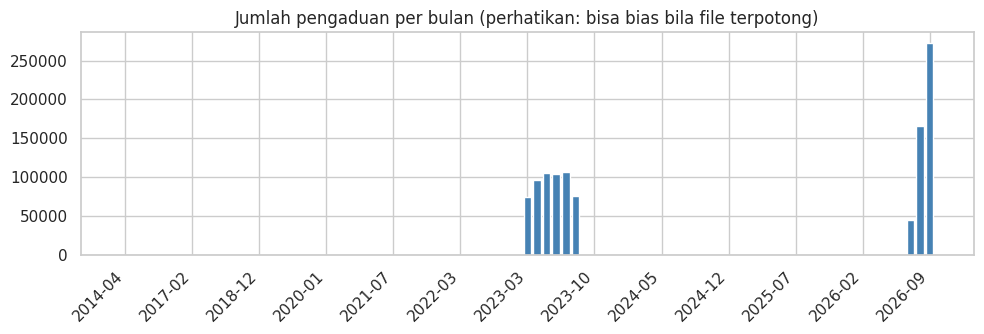

In [ ]:
# [CELL 4] Audit keterbatasan data: pemotongan file (batas baris Excel) & rentang tanggal
def parse_dates(s):
    s = s.astype(str)
    d = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
    m = d.isna()
    if m.any():
        d.loc[m] = pd.to_datetime(s[m], format="%Y-%m-%d", errors="coerce")
    return d

n_rows = len(df)
TRUNCATED = n_rows >= EXCEL_ROW_LIMIT - 5
print(f"Jumlah baris data: {n_rows:,} (batas baris data Excel = {EXCEL_ROW_LIMIT:,})")
if TRUNCATED:
    print("\n[PERINGATAN] Jumlah baris sama/hampir sama dengan batas Excel. File kemungkinan TERPOTONG (baris sesudahnya hilang).")
    print("  - Penyebab umum: CSV dibuka dan disimpan ulang lewat Excel. Format tanggal m/d/yyyy juga khas hasil simpan Excel.")
    print("  - Dampak: sampel bukan acak dari populasi penuh, urutan tanggal tidak teratur, tren waktu dan proporsi kelas bisa bias.")
    print("  - Solusi: unduh ulang CSV asli dari CFPB dan baca langsung dengan pandas (jangan lewat Excel),")
    print("            atau unduh per tahun/produk lalu gabungkan dengan pd.concat.")
else:
    print("Jumlah baris di bawah batas Excel: tidak ada indikasi pemotongan oleh Excel.")

if DATE_COL in df.columns:
    dts = parse_dates(df[DATE_COL])
    print(f"\nRentang '{DATE_COL}': {dts.min().date() if dts.notna().any() else '-'} s.d. {dts.max().date() if dts.notna().any() else '-'} | tanggal gagal diparse: {int(dts.isna().sum()):,}")
    print("Terurut naik:", bool(dts.is_monotonic_increasing), "| terurut turun:", bool(dts.is_monotonic_decreasing))
    print("Tanggal 3 baris pertama :", [str(x.date()) for x in dts.dropna().head(3)])
    print("Tanggal 3 baris terakhir:", [str(x.date()) for x in dts.dropna().tail(3)])
    yearly = dts.dt.year.value_counts().sort_index()
    display(yearly.to_frame("jumlah pengaduan").T)
    monthly = dts.dt.to_period("M").value_counts().sort_index()
    if len(monthly) > 1:
        fig, ax = plt.subplots(figsize=(10, 3.5))
        ax.bar(range(len(monthly)), monthly.values, color="steelblue")
        step = max(1, len(monthly) // 12)
        ax.set_xticks(range(0, len(monthly), step))
        ax.set_xticklabels([str(p) for p in monthly.index[::step]], rotation=45, ha="right")
        ax.set_title("Jumlah pengaduan per bulan (perhatikan: bisa bias bila file terpotong)")
        plt.tight_layout(); plt.show()
    df["_date"] = dts

In [ ]:
# [CELL 5] Audit kolom berpotensi bocor (data leakage): kekuatan asosiasi dengan target (Cramér's V, bias-corrected)
def collapse_rare(s, min_count=30):
    s = s.fillna("NA").astype(str)
    vc = s.value_counts()
    keep = set(vc[vc >= min_count].index)
    return s.where(s.isin(keep), "Other")

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if min(ct.shape) < 2:
        return np.nan
    chi2_ = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    phi2 = chi2_ / n
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1); kc = k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1))))

AUDIT_N = 200_000
aud = df[df[TARGET_COL].notna()]
aud = aud.sample(min(AUDIT_N, len(aud)), random_state=RANDOM_STATE)
rows = []
for col in [c for c in TEXT_COLS + CAT_COLS + LEAKY_COLS if c in aud.columns]:
    v = cramers_v(collapse_rare(aud[col]), aud[TARGET_COL].astype(str))
    status = "DIKELUARKAN (pasca-respons)" if col in LEAKY_COLS else ("teks" if col in TEXT_COLS else "fitur kategorikal")
    rows.append({"Kolom": col, "Cramér's V terhadap target": round(v, 4), "Kategori unik": int(aud[col].nunique()), "Peran": status})
display(pd.DataFrame(rows).sort_values("Cramér's V terhadap target", ascending=False).reset_index(drop=True))

if "Timely response?" in df.columns:
    print("\nCrosstab 'Timely response?' vs target (persen per baris):")
    display((pd.crosstab(aud["Timely response?"].fillna("NA"), aud[TARGET_COL], normalize="index") * 100).round(1))
print("\nKESIMPULAN: kolom bertanda DIKELUARKAN dihasilkan bersamaan dengan/ setelah respons perusahaan, sehingga tidak tersedia "
      "saat model dipakai untuk memprediksi. Memakainya akan membuat skor terlihat bagus tetapi tidak valid.")

,Kolom,Cramér's V terhadap target,Kategori unik,Peran
0,Timely response?,0.6626,2,DIKELUARKAN (pasca-respons)
1,Product,0.3916,15,teks
2,Company,0.3682,1611,fitur kategorikal
3,Issue,0.2959,85,teks
4,Company public response,0.2730,10,DIKELUARKAN (pasca-respons)
5,Sub-issue,0.2671,203,teks
6,Sub-product,0.2282,56,teks
7,Tags,0.0880,3,fitur kategorikal
8,Submitted via,0.0730,4,fitur kategorikal
9,State,0.0600,59,fitur kategorikal



Crosstab 'Timely response?' vs target (persen per baris):


Company response to consumer,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,In progress,Untimely response
Timely response?,,,,,
No,50.7,2.4,2.9,0.0,43.9
Yes,46.0,0.9,27.6,25.4,0.0



KESIMPULAN: kolom bertanda DIKELUARKAN dihasilkan bersamaan dengan/ setelah respons perusahaan, sehingga tidak tersedia saat model dipakai untuk memprediksi. Memakainya akan membuat skor terlihat bagus tetapi tidak valid.


In [ ]:
# [CELL 6] Membentuk teks (X) & target (y), audit kualitas, dan log pembersihan
TEXT_COLS_PRESENT = [c for c in TEXT_COLS if c in df.columns]
CAT_PRESENT = [c for c in CAT_COLS if c in df.columns]
narr_col = next((c for c in NARRATIVE_CANDIDATES if c in df.columns), None)

def concat_cols(frame, cols):
    out = frame[cols[0]].fillna("").astype(str)
    for c in cols[1:]:
        out = out + " " + frame[c].fillna("").astype(str)
    return out

log = [("Data awal", len(df))]
base = df[df[TARGET_COL].notna()].copy()
log.append(("Buang target kosong", len(base)))
base["target"] = base[TARGET_COL].astype(str).str.strip()
struct_text = concat_cols(base, TEXT_COLS_PRESENT)

if narr_col is not None and base[narr_col].notna().mean() > 0.05:
    TEXT_MODE = "narrative"
    base = base[base[narr_col].notna()].copy()
    base["text_raw"] = base[narr_col].astype(str) + " " + struct_text.loc[base.index]
    log.append(("Hanya baris dengan narasi", len(base)))
else:
    TEXT_MODE = "structured"
    base["text_raw"] = struct_text
    print("[INFO] Kolom narasi tidak tersedia -> teks dibentuk dari", TEXT_COLS_PRESENT)

base["text_raw"] = base["text_raw"].str.strip()
base = base[base["text_raw"] != ""]
log.append(("Buang teks kosong", len(base)))
for c in CAT_PRESENT:
    base[c] = base[c].fillna("Unknown").astype(str).str.strip().replace("", "Unknown")

vc = base["target"].value_counts()
rare = vc[vc < MIN_CLASS_COUNT].index.tolist()
if rare:
    print(f"Kelas dibuang karena < {MIN_CLASS_COUNT} sampel: {rare}")
    base = base[~base["target"].isin(rare)]
log.append((f"Buang kelas langka (< {MIN_CLASS_COUNT})", len(base)))

keep_cols = ["text_raw", "target"] + CAT_PRESENT + ([ID_COL] if ID_COL in base.columns else []) + (["_date"] if "_date" in base.columns else [])
df_all = base[keep_cols].reset_index(drop=True)
del base

print("Mode teks:", TEXT_MODE)
print("\n--- LOG PEMBERSIHAN ---")
display(pd.DataFrame(log, columns=["Langkah", "Jumlah baris"]))
n_dup_text = int(df_all["text_raw"].duplicated().sum())
print(f"Teks duplikat: {n_dup_text:,} ({n_dup_text/len(df_all)*100:.1f}%) | teks unik: {df_all['text_raw'].nunique():,}")
if TEXT_MODE == "structured":
    print("Duplikasi teks WAJAR pada mode terstruktur (banyak pengaduan berjenis sama), sehingga baris tidak dibuang.")
display(df_all.head(3))

[INFO] Kolom narasi tidak tersedia -> teks dibentuk dari ['Product', 'Sub-product', 'Issue', 'Sub-issue']
Mode teks: structured

--- LOG PEMBERSIHAN ---


,Langkah,Jumlah baris
0,Data awal,1048575
1,Buang target kosong,1048573
2,Buang teks kosong,1048573
3,Buang kelas langka (< 50),1048573


Teks duplikat: 1,047,090 (99.9%) | teks unik: 1,483
Duplikasi teks WAJAR pada mode terstruktur (banyak pengaduan berjenis sama), sehingga baris tidak dibuang.


,text_raw,target,Company,State,Submitted via,Tags,Complaint ID,_date
0,Credit reporting or other personal consumer reports Credit reporting Problem with a company's in...,Closed with non-monetary relief,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",MS,Web,Unknown,11485110,2025-01-12
1,Credit reporting or other personal consumer reports Credit reporting Problem with a company's in...,Closed with explanation,Experian Information Solutions Inc.,MS,Web,Unknown,11489006,2025-01-12
2,Credit reporting or other personal consumer reports Credit reporting Problem with a company's in...,Closed with non-monetary relief,"EQUIFAX, INC.",MS,Web,Unknown,11488317,2025-01-12


## 3. Exploratory Data Analysis (EDA) & Initial Findings
1. **Distribusi kelas target** (menentukan pemilihan metrik).
2. **Panjang teks**.
3. **Kapasitas informasi fitur**: seberapa jauh target dapat ditebak dari tiap kelompok fitur (menjelaskan batas performa).
4. **Hubungan perusahaan–target** dan **tren waktu**. Kata/n-gram teratas ada di bagian 4b (setelah preprocessing).

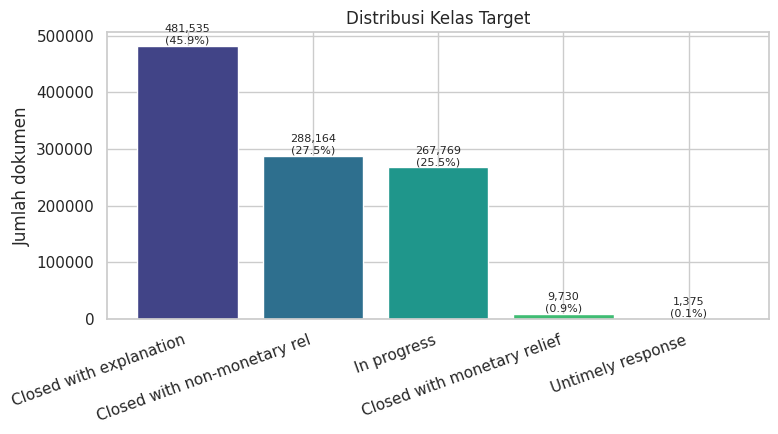

Kelas mayoritas : Closed with explanation (481,535 dok, 45.9%)
Kelas minoritas : Untimely response (1,375 dok, 0.13%)
Imbalance ratio : 350.21  -> imbalance berat
Tebakan 'selalu Closed with explanation': akurasi 0.4592, F1-macro 0.1259
Akurasi saja menyesatkan pada data ini; gunakan F1-macro, balanced accuracy, MCC, dan PR-AUC.


In [ ]:
# [CELL 7] EDA 1: Distribusi kelas target + batas bawah (dummy)
vc = df_all["target"].value_counts()
total = len(df_all)
fig, ax = plt.subplots(figsize=(8, 4.5))
colors_ = plt.cm.viridis(np.linspace(0.2, 0.85, len(vc)))
bars = ax.bar(range(len(vc)), vc.values, color=colors_)
ax.set_xticks(range(len(vc)))
ax.set_xticklabels([str(i)[:28] for i in vc.index], rotation=20, ha="right")
ax.set_title("Distribusi Kelas Target"); ax.set_ylabel("Jumlah dokumen")
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/total*100:.1f}%)", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

IMB_RATIO = vc.max() / vc.min()
MAJ_ACC = vc.max() / total
MAJ_LABEL = vc.idxmax()
MAJ_F1 = f1_score(df_all["target"], [MAJ_LABEL] * total, average="macro", zero_division=0)
level = "relatif seimbang" if IMB_RATIO < 1.5 else ("imbalance ringan-sedang" if IMB_RATIO < 5 else "imbalance berat")
print(f"Kelas mayoritas : {MAJ_LABEL} ({vc.max():,} dok, {MAJ_ACC*100:.1f}%)")
print(f"Kelas minoritas : {vc.idxmin()} ({vc.min():,} dok, {vc.min()/total*100:.2f}%)")
print(f"Imbalance ratio : {IMB_RATIO:.2f}  -> {level}")
print(f"Tebakan 'selalu {MAJ_LABEL}': akurasi {MAJ_ACC:.4f}, F1-macro {MAJ_F1:.4f}")
print("Akurasi saja menyesatkan pada data ini; gunakan F1-macro, balanced accuracy, MCC, dan PR-AUC.")

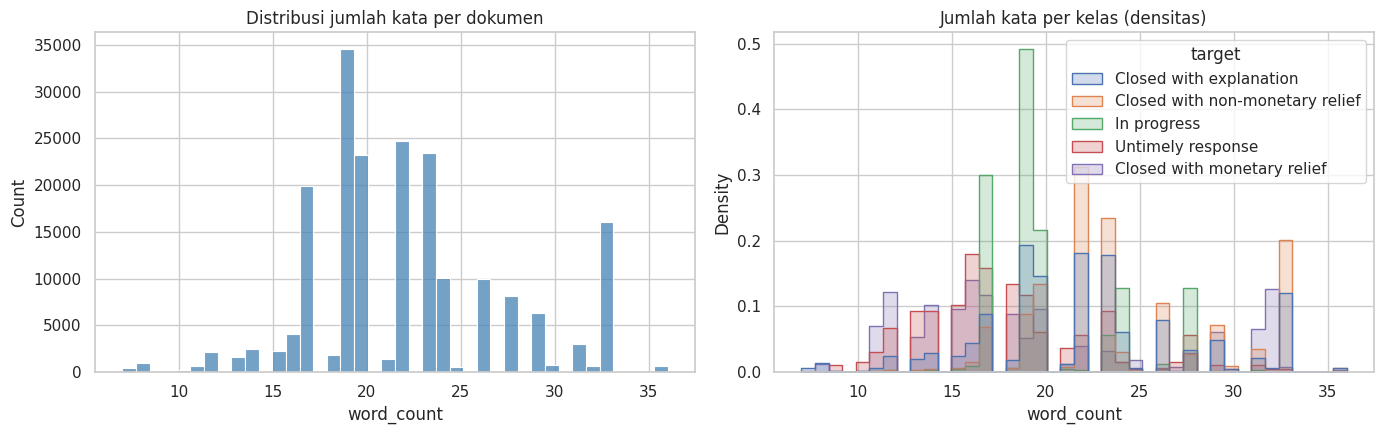

,count,mean,std,min,25%,50%,75%,max
word_count,200000.0,22.09,5.17,7.0,19.0,22.0,24.0,36.0


,count,mean,median,min,max
target,,,,,
Closed with explanation,92007,21.98,22.0,7,36
Closed with monetary relief,1881,19.41,17.0,7,36
Closed with non-monetary relief,55139,24.12,23.0,7,36
In progress,50704,20.22,19.0,8,34
Untimely response,269,17.91,17.0,9,33


Dokumen sangat pendek (<5 kata): 0.0%


In [ ]:
# [CELL 8] EDA 2: Panjang teks
eda = df_all.sample(min(200_000, len(df_all)), random_state=RANDOM_STATE).copy()
eda["word_count"] = eda["text_raw"].str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=eda, x="word_count", bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Distribusi jumlah kata per dokumen")
sns.histplot(data=eda, x="word_count", hue="target", element="step", stat="density", common_norm=False, bins=40, ax=axes[1])
axes[1].set_title("Jumlah kata per kelas (densitas)")
plt.tight_layout(); plt.show()
display(eda["word_count"].describe().round(2).to_frame("word_count").T)
display(eda.groupby("target")["word_count"].agg(["count", "mean", "median", "min", "max"]).round(2))
print(f"Dokumen sangat pendek (<5 kata): {(eda['word_count'] < 5).mean()*100:.1f}%")

In [ ]:
# [CELL 9] EDA 3: Kapasitas informasi fitur (tabel-lookup eksploratif, BUKAN model final)
# Untuk tiap kelompok fitur: prediksi = kelas mayoritas pada kombinasi fitur yang sama di data latih.
def lookup_eval(frame, cols, seed=RANDOM_STATE):
    tr, te = train_test_split(frame[cols + ["target"]], test_size=0.2, stratify=frame["target"], random_state=seed)
    maj = tr["target"].mode()[0]
    g = tr.groupby(cols + ["target"]).size().rename("n").reset_index()
    best = g.sort_values("n", ascending=False).drop_duplicates(cols)[cols + ["target"]].rename(columns={"target": "pred"})
    m = te.merge(best, on=cols, how="left")
    covered = m["pred"].notna().mean()
    m["pred"] = m["pred"].fillna(maj)
    return {"Kombinasi unik (latih)": int(len(best)), "Akurasi": accuracy_score(m["target"], m["pred"]),
            "F1 macro": f1_score(m["target"], m["pred"], average="macro", zero_division=0),
            "Balanced Acc": balanced_accuracy_score(m["target"], m["pred"]),
            "Cakupan kombinasi di uji": covered}

explore = df_all.sample(min(EXPLORE_N, len(df_all)), random_state=RANDOM_STATE)
feature_sets = {"Teks saja (versi 1)": ["text_raw"]}
cum = ["text_raw"]
for c in CAT_PRESENT:
    cum = cum + [c]
    feature_sets["+ " + ", ".join(cum[1:])] = list(cum)
info_rows = []
for name, cols in feature_sets.items():
    r = lookup_eval(explore, cols); r["Fitur"] = name; info_rows.append(r)
df_info = pd.DataFrame(info_rows).set_index("Fitur").round(4)
display(df_info)
print("Cara membaca: bila akurasi/F1 naik jelas saat fitur ditambah (dan cakupan kombinasi masih tinggi), fitur tersebut membawa informasi baru. "
      "Bila cakupan turun tajam, kombinasi terlalu jarang dan model perlu generalisasi (itulah fungsi ML dibanding tabel-lookup).")

,Kombinasi unik (latih),Akurasi,F1 macro,Balanced Acc,Cakupan kombinasi di uji
Fitur,,,,,
Teks saja (versi 1),1125,0.5761,0.3670,0.3801,0.9989
+ Company,14228,0.7125,0.5484,0.5147,0.9619
"+ Company, State",34382,0.7061,0.4902,0.4704,0.8908
"+ Company, State, Submitted via",35822,0.7064,0.4851,0.4656,0.8846
"+ Company, State, Submitted via, Tags",38854,0.7054,0.4837,0.4643,0.8723


Cara membaca: bila akurasi/F1 naik jelas saat fitur ditambah (dan cakupan kombinasi masih tinggi), fitur tersebut membawa informasi baru. Bila cakupan turun tajam, kombinasi terlalu jarang dan model perlu generalisasi (itulah fungsi ML dibanding tabel-lookup).


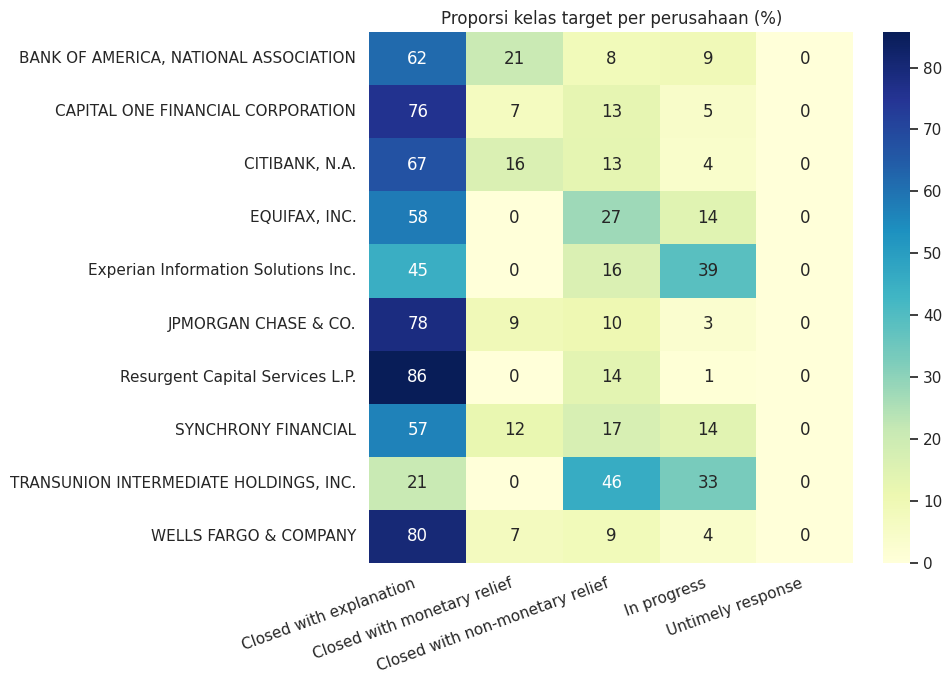

Selisih proporsi tertinggi-terendah antar perusahaan (poin persen) per kelas:
 target
Closed with explanation            64.7
Closed with monetary relief        20.6
Closed with non-monetary relief    37.2
In progress                        37.9
Untimely response                   0.3
Jika selisih besar, perusahaan adalah fitur yang informatif (dipakai sebagai fitur kategorikal).


In [ ]:
# [CELL 10] EDA 4: Hubungan perusahaan-target (heatmap)
if "Company" in df_all.columns:
    top_comp = df_all["Company"].value_counts().head(10).index
    sub = df_all[df_all["Company"].isin(top_comp)]
    ct = pd.crosstab(sub["Company"], sub["target"], normalize="index") * 100
    plt.figure(figsize=(10, 4 + 0.3 * len(ct)))
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlGnBu")
    plt.title("Proporsi kelas target per perusahaan (%)"); plt.xlabel(""); plt.ylabel("")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
    spread = (ct.max() - ct.min()).round(1)
    print("Selisih proporsi tertinggi-terendah antar perusahaan (poin persen) per kelas:\n", spread.to_string())
    print("Jika selisih besar, perusahaan adalah fitur yang informatif (dipakai sebagai fitur kategorikal).")

In [ ]:
# [CELL 11] Data kerja (sampel stratified) & interpretasi EDA otomatis
if SAMPLE_N and len(df_all) > SAMPLE_N:
    df_model, _ = train_test_split(df_all, train_size=SAMPLE_N, stratify=df_all["target"], random_state=RANDOM_STATE)
    df_model = df_model.reset_index(drop=True)
else:
    df_model = df_all.copy()
print(f"Data kerja: {len(df_model):,} baris dari {len(df_all):,} (sampel stratified; proporsi kelas terjaga).")

vc = df_all["target"].value_counts()
print("\n=== INTERPRETASI TEMUAN EDA ===")
print(f"1. Distribusi label: {len(vc)} kelas; mayoritas '{vc.idxmax()}' ({vc.max()/len(df_all)*100:.1f}%); imbalance ratio {vc.max()/vc.min():.1f}. "
      f"Konsekuensi: akurasi bukan metrik tunggal (tebakan mayoritas = {MAJ_ACC:.3f}); gunakan F1-macro, balanced accuracy, MCC, PR-AUC.")
print(f"2. Panjang teks: median {eda['word_count'].median():.0f} kata, maks {eda['word_count'].max()}. Teks pendek -> TF-IDF dan n-gram (1,2) layak diuji.")
print(f"3. Kosakata teks unik: {df_all['text_raw'].nunique():,} kombinasi dari {len(df_all):,} baris "
      f"({df_all['text_raw'].nunique()/len(df_all)*100:.3f}%).")
first, last = df_info.iloc[0], df_info.iloc[-1]
print(f"4. Kapasitas informasi: akurasi tabel-lookup {first['Akurasi']:.3f} (teks saja) -> {last['Akurasi']:.3f} (semua fitur); "
      f"F1-macro {first['F1 macro']:.3f} -> {last['F1 macro']:.3f}.")
if TEXT_MODE == "structured":
    gain = last["F1 macro"] - first["F1 macro"]
    msg = ("atribut kategorikal menambah informasi (F1-macro tabel-lookup naik %+.3f)" % gain) if gain > 0.01 else ("atribut kategorikal belum menambah informasi yang jelas pada tabel-lookup (selisih F1-macro %+.3f)" % gain)
    print("5. CATATAN: tanpa kolom narasi, teks hanya jenis masalah; " + msg + ". Pengaduan dengan fitur identik tetap dapat berlabel berbeda sehingga ada batas performa alami.")
if TRUNCATED:
    print("6. PERINGATAN: file terpotong di batas Excel; hasil berlaku untuk sampel ini, bukan populasi penuh CFPB.")

Data kerja: 300,000 baris dari 1,048,573 (sampel stratified; proporsi kelas terjaga).

=== INTERPRETASI TEMUAN EDA ===
1. Distribusi label: 5 kelas; mayoritas 'Closed with explanation' (45.9%); imbalance ratio 350.2. Konsekuensi: akurasi bukan metrik tunggal (tebakan mayoritas = 0.459); gunakan F1-macro, balanced accuracy, MCC, PR-AUC.
2. Panjang teks: median 22 kata, maks 36. Teks pendek -> TF-IDF dan n-gram (1,2) layak diuji.
3. Kosakata teks unik: 1,483 kombinasi dari 1,048,573 baris (0.141%).
4. Kapasitas informasi: akurasi tabel-lookup 0.576 (teks saja) -> 0.705 (semua fitur); F1-macro 0.367 -> 0.484.
5. CATATAN: tanpa kolom narasi, teks hanya jenis masalah; atribut kategorikal menambah informasi (F1-macro tabel-lookup naik +0.117). Pengaduan dengan fitur identik tetap dapat berlabel berbeda sehingga ada batas performa alami.
6. PERINGATAN: file terpotong di batas Excel; hasil berlaku untuk sampel ini, bukan populasi penuh CFPB.


# PERTEMUAN 3 — Preprocessing, TF-IDF & Baseline
**Checkpoint:** cleaning, pemisahan data **sebelum** TF-IDF di-fit, baseline Logistic Regression, metrik evaluasi, temuan awal.

## 4. Preprocessing Teks & Protokol Pencegahan Data Leakage
1. **Case folding** (lowercase).
2. **Hapus URL & token sensor `XXXX`** (CFPB menyamarkan data pribadi).
3. **Hapus angka & tanda baca**.
4. **Normalisasi spasi**.
5. **Stopword TIDAK dihapus:** teks sangat pendek dan kata negasi ("not", "no") membawa makna (mis. "debt is not yours"). Kata terlalu jarang dibuang lewat `min_df`.
6. **Stemming/lemmatization:** tidak diterapkan agar baseline sederhana.

**Protokol anti-leakage**
* Langkah 1–4 bersifat *stateless* (per dokumen), aman dilakukan sebelum split.
* Data dibagi **train / validation / test = 60 / 20 / 20** (stratified). **Test dikunci** dan baru dipakai sekali di bagian UTS.
* `TfidfVectorizer` dan `OneHotEncoder` berada **di dalam Pipeline**, sehingga di-fit hanya pada data latih (dan di-fit ulang per fold saat CV).
* P3–P4 dievaluasi pada **validation**; P5 dan P7 memakai **cross-validation pada data dev (train+val)**.

In [ ]:
# [CELL 12] Preprocessing stateless
def clean_text(s):
    s = s.fillna("").astype(str).str.lower()
    s = s.str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
    s = s.str.replace(r"x{2,}", " ", regex=True)
    s = s.str.replace(r"[^a-z\s]", " ", regex=True)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s

df_model["text_clean"] = clean_text(df_model["text_raw"])
before = len(df_model)
df_model = df_model[df_model["text_clean"] != ""].reset_index(drop=True)
print(f"Dokumen kosong setelah cleaning dibuang: {before - len(df_model)} | jumlah akhir: {len(df_model):,}")
print("\n--- SEBELUM & SESUDAH ---")
for _, r in df_model[["text_raw", "text_clean"]].head(3).iterrows():
    print("SEBELUM:", str(r["text_raw"])[:160]); print("SESUDAH:", r["text_clean"][:160]); print("-" * 60)

Dokumen kosong setelah cleaning dibuang: 0 | jumlah akhir: 300,000

--- SEBELUM & SESUDAH ---
SEBELUM: Credit reporting or other personal consumer reports Credit reporting Improper use of your report Credit inquiries on your report that you don't recognize
SESUDAH: credit reporting or other personal consumer reports credit reporting improper use of your report credit inquiries on your report that you don t recognize
------------------------------------------------------------
SEBELUM: Credit reporting, credit repair services, or other personal consumer reports Credit reporting Problem with a credit reporting company's investigation into an ex
SESUDAH: credit reporting credit repair services or other personal consumer reports credit reporting problem with a credit reporting company s investigation into an exis
------------------------------------------------------------
SEBELUM: Credit reporting, credit repair services, or other personal consumer reports Credit reporting Incorrect infor

In [ ]:
# [CELL 13] Split train / validation / test (stratified) — test dikunci
FEATURES = ["text_clean"] + CAT_PRESENT
X = df_model[FEATURES]
y = df_model["target"]

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=VAL_SIZE, stratify=y_dev, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test (DIKUNCI): {len(X_test):,}")
dist = pd.DataFrame({"Seluruh (%)": y.value_counts(normalize=True) * 100, "Train (%)": y_train.value_counts(normalize=True) * 100,
                     "Validation (%)": y_val.value_counts(normalize=True) * 100, "Test (%)": y_test.value_counts(normalize=True) * 100}).round(2)
print("\nProporsi kelas (bukti stratifikasi):")
display(dist)
print("Variabel X_test / y_test TIDAK dipakai lagi sampai bagian UTS.")

Train: 180,000 | Validation: 60,000 | Test (DIKUNCI): 60,000

Proporsi kelas (bukti stratifikasi):


,Seluruh (%),Train (%),Validation (%),Test (%)
target,,,,
Closed with explanation,45.92,45.92,45.92,45.92
Closed with non-monetary relief,27.48,27.48,27.48,27.48
In progress,25.54,25.54,25.54,25.54
Closed with monetary relief,0.93,0.93,0.93,0.93
Untimely response,0.13,0.13,0.13,0.13


Variabel X_test / y_test TIDAK dipakai lagi sampai bagian UTS.


In [ ]:
# [CELL 14] Fungsi pipeline & metrik (dipakai di seluruh notebook)
def make_prep(struct=True, ngram=(1, 1), max_features=MAX_FEATURES, min_df=2):
    parts = [("txt", TfidfVectorizer(max_features=max_features, ngram_range=ngram, min_df=min_df, sublinear_tf=True), "text_clean")]
    if struct and CAT_PRESENT:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), CAT_PRESENT))
    return ColumnTransformer(parts)

def get_scores(model, X_):
    if hasattr(model, "predict_proba"):
        try: return model.predict_proba(X_)
        except Exception: pass
    if hasattr(model, "decision_function"):
        try: return model.decision_function(X_)
        except Exception: pass
    return None

def pr_auc_macro(model, X_, y_true):
    s = get_scores(model, X_)
    if s is None: return np.nan
    classes_ = model.classes_
    Yb = label_binarize(y_true, classes=classes_)
    if Yb.shape[1] == 1: Yb = np.hstack([1 - Yb, Yb])
    if s.ndim == 1: s = np.column_stack([-s, s])
    vals = [average_precision_score(Yb[:, i], s[:, i]) for i in range(Yb.shape[1]) if Yb[:, i].sum() > 0]
    return float(np.mean(vals))

def evaluate(model, X_, y_true, name, fit_time=np.nan):
    yp = model.predict(X_)
    p, r, f, _ = precision_recall_fscore_support(y_true, yp, average="macro", zero_division=0)
    return {"Model": name, "Accuracy": accuracy_score(y_true, yp), "Balanced Acc": balanced_accuracy_score(y_true, yp),
            "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f,
            "F1 (weighted)": f1_score(y_true, yp, average="weighted", zero_division=0),
            "MCC": matthews_corrcoef(y_true, yp), "PR-AUC (macro)": pr_auc_macro(model, X_, y_true),
            "Waktu latih (s)": fit_time}, yp

def stratified_sample(X_, y_, n, seed=RANDOM_STATE):
    if n is None or len(X_) <= n: return X_, y_
    Xs, _, ys, _ = train_test_split(X_, y_, train_size=n, stratify=y_, random_state=seed)
    return Xs, ys

LABELS = sorted(y.unique())
print("Kelas:", LABELS)

Kelas: ['Closed with explanation', 'Closed with monetary relief', 'Closed with non-monetary relief', 'In progress', 'Untimely response']


## 5. Baseline
* **Dummy (mayoritas):** batas bawah. Model apa pun harus mengalahkannya pada F1-macro.
* **Baseline:** TF-IDF (hanya teks, seperti versi 1) + Logistic Regression.

,Model,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),MCC,PR-AUC (macro),Waktu latih (s)
0,Dummy (kelas mayoritas),0.4592,0.2000,0.0918,0.2000,0.1259,0.2890,0.0000,0.2000,NaN
1,Baseline: TF-IDF(teks) + Logistic Regression,0.5698,0.3539,0.3313,0.3539,0.3242,0.5368,0.3557,0.4031,17.0908



=== CLASSIFICATION REPORT BASELINE (validation) ===
                                 precision    recall  f1-score   support

        Closed with explanation       0.59      0.56      0.57     27554
    Closed with monetary relief       0.00      0.00      0.00       557
Closed with non-monetary relief       0.49      0.25      0.33     16489
                    In progress       0.58      0.97      0.72     15322
              Untimely response       0.00      0.00      0.00        78

                       accuracy                           0.57     60000
                      macro avg       0.33      0.35      0.32     60000
                   weighted avg       0.55      0.57      0.54     60000



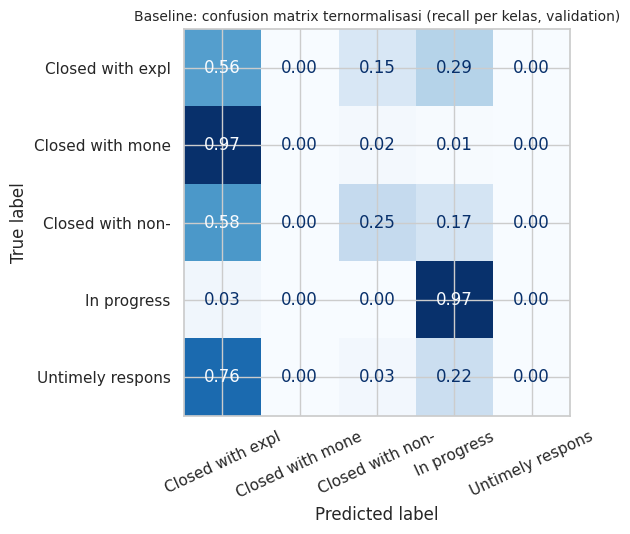

In [ ]:
# [CELL 15] Baseline & dummy — dilatih pada TRAIN, dievaluasi pada VALIDATION
BASE_NAME = "Baseline: TF-IDF(teks) + Logistic Regression"
results, fitted, preds = [], {}, {}

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
r, yp = evaluate(dummy, X_val, y_val, "Dummy (kelas mayoritas)"); results.append(r)

baseline = Pipeline([("prep", make_prep(struct=False)), ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE))])
t0 = time.time(); baseline.fit(X_train, y_train); dur = time.time() - t0
r, yp = evaluate(baseline, X_val, y_val, BASE_NAME, dur); results.append(r)
fitted[BASE_NAME], preds[BASE_NAME] = baseline, yp

display(pd.DataFrame(results).round(4))
print("\n=== CLASSIFICATION REPORT BASELINE (validation) ===")
print(classification_report(y_val, yp, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, yp, labels=LABELS, normalize="true"), display_labels=[str(l)[:16] for l in LABELS]).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=25, values_format=".2f")
ax.set_title("Baseline: confusion matrix ternormalisasi (recall per kelas, validation)", fontsize=10)
plt.tight_layout(); plt.show()

### 4b. EDA lanjutan setelah preprocessing (kata & bigram teratas)

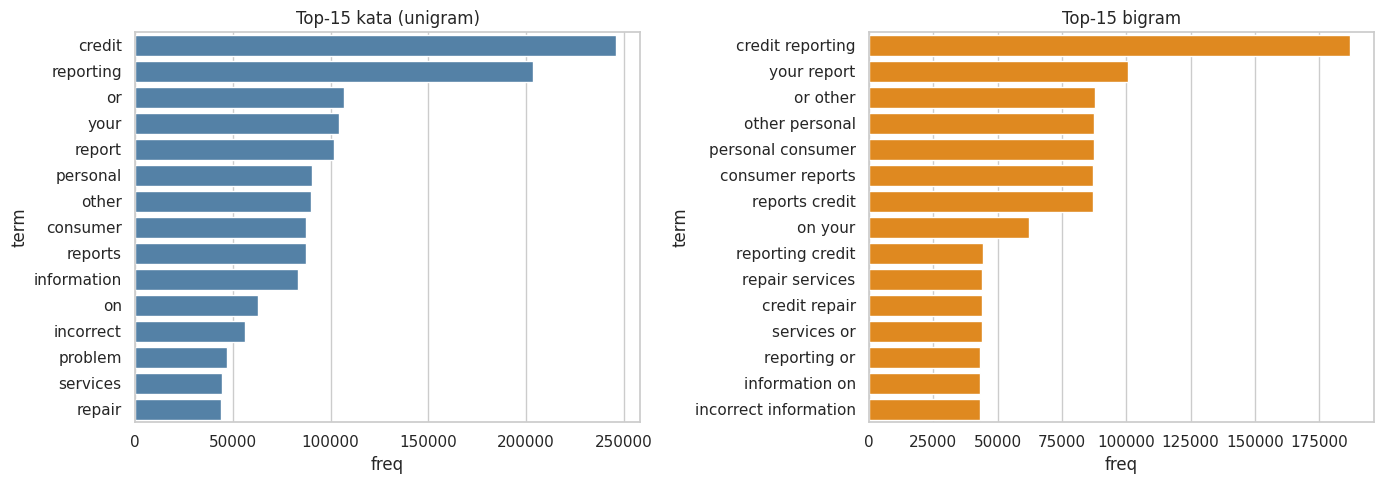

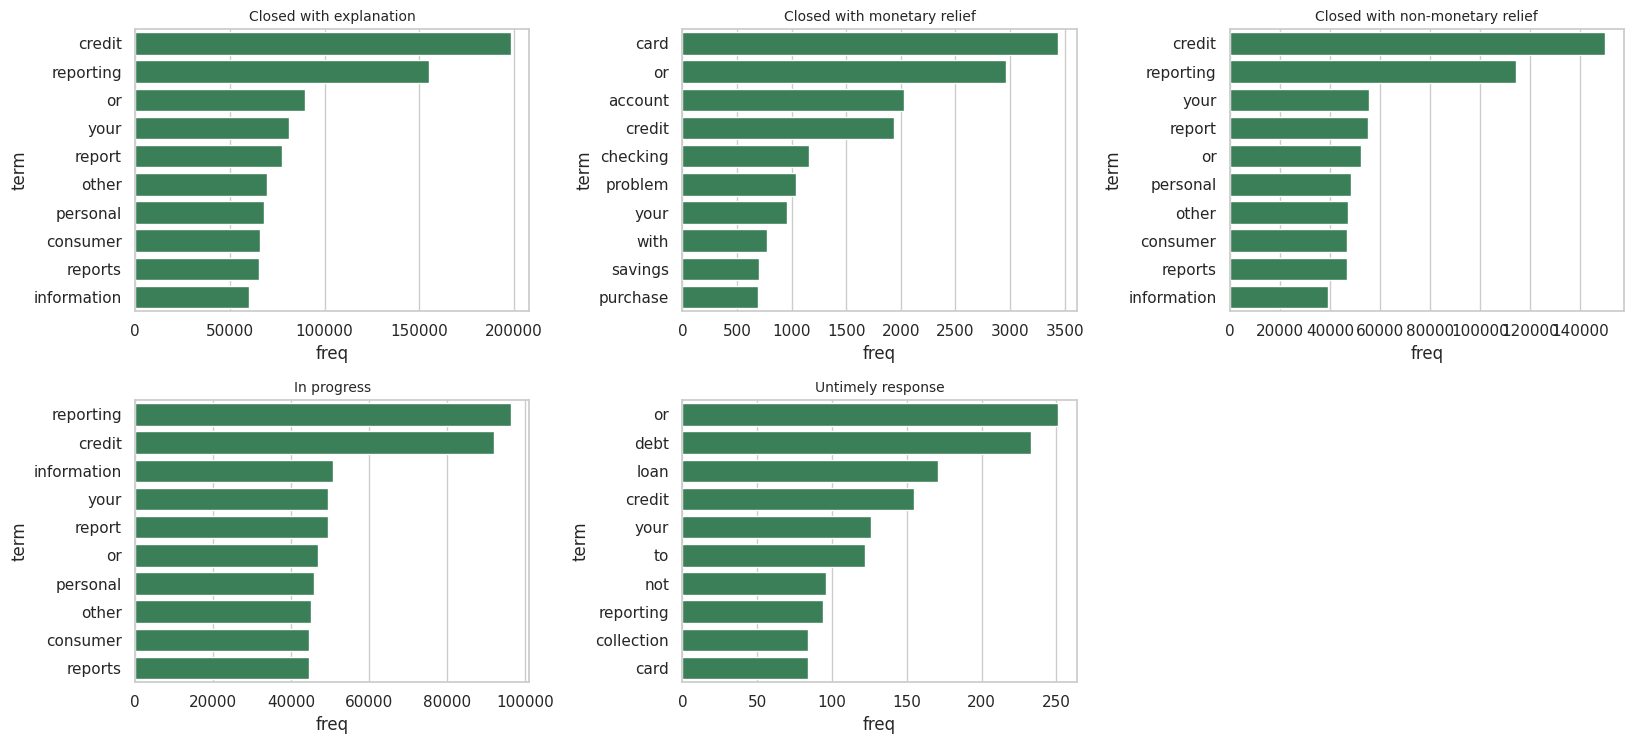

In [ ]:
# [CELL 16] Kata dan bigram teratas (data latih saja)
def top_terms(texts, ngram=(1, 1), n=TOP_N):
    cv = CountVectorizer(ngram_range=ngram, min_df=2)
    Xc = cv.fit_transform(texts)
    freq = np.asarray(Xc.sum(axis=0)).ravel()
    terms = np.array(cv.get_feature_names_out())
    idx = freq.argsort()[::-1][:n]
    return pd.DataFrame({"term": terms[idx], "freq": freq[idx]})

tr_txt = X_train["text_clean"].sample(min(100_000, len(X_train)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
uni, bi = top_terms(tr_txt, (1, 1)), top_terms(tr_txt, (2, 2))
sns.barplot(data=uni, y="term", x="freq", ax=axes[0], color="steelblue"); axes[0].set_title(f"Top-{TOP_N} kata (unigram)")
sns.barplot(data=bi, y="term", x="freq", ax=axes[1], color="darkorange"); axes[1].set_title(f"Top-{TOP_N} bigram")
plt.tight_layout(); plt.show()

classes_ = sorted(y_train.unique()); ncols = min(3, len(classes_)); nrows = int(np.ceil(len(classes_) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows), squeeze=False)
for ax, c in zip(axes.ravel(), classes_):
    t = top_terms(X_train.loc[y_train == c, "text_clean"].head(100_000), (1, 1), 10)
    sns.barplot(data=t, y="term", x="freq", ax=ax, color="seagreen"); ax.set_title(str(c)[:35], fontsize=10)
for ax in axes.ravel()[len(classes_):]: ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# [CELL 17] Temuan awal & kelemahan baseline (otomatis)
rep = classification_report(y_val, preds[BASE_NAME], output_dict=True, zero_division=0)
rec = {c: rep[c]["recall"] for c in LABELS if c in rep}
bl = results[1]
weak = [c for c, v in rec.items() if v < 0.05]
print("=== TEMUAN AWAL P3 ===")
print(f"1. Baseline: akurasi {bl['Accuracy']:.4f}, F1-macro {bl['F1 (macro)']:.4f}, balanced acc {bl['Balanced Acc']:.4f}, MCC {bl['MCC']:.4f}; "
      f"dummy F1-macro {results[0]['F1 (macro)']:.4f}.")
print(f"2. Selisih akurasi vs F1-macro = {bl['Accuracy'] - bl['F1 (macro)']:.4f}: model condong ke kelas besar, akurasi menutupi kelemahan pada kelas kecil.")
print(f"3. Kelas dengan recall < 0,05 pada baseline: {weak if weak else 'tidak ada'}.")
worst = min(rec, key=rec.get)
print(f"4. Kelas tersulit: '{worst}' (recall {rec[worst]:.3f}).")
print("5. FOKUS PERBAIKAN: (a) tambah fitur kategorikal, (b) bandingkan kandidat model (P4), (c) tangani imbalance dan validasi stabilitas (P5).")

=== TEMUAN AWAL P3 ===
1. Baseline: akurasi 0.5698, F1-macro 0.3242, balanced acc 0.3539, MCC 0.3557; dummy F1-macro 0.1259.
2. Selisih akurasi vs F1-macro = 0.2456: model condong ke kelas besar, akurasi menutupi kelemahan pada kelas kecil.
3. Kelas dengan recall < 0,05 pada baseline: ['Closed with monetary relief', 'Untimely response'].
4. Kelas tersulit: 'Closed with monetary relief' (recall 0.000).
5. FOKUS PERBAIKAN: (a) tambah fitur kategorikal, (b) bandingkan kandidat model (P4), (c) tangani imbalance dan validasi stabilitas (P5).


# PERTEMUAN 4 — Kandidat Model & Perbandingan Awal
**Checkpoint:** minimal 1–2 kandidat tambahan, tabel perbandingan Baseline vs Kandidat, 3–5 temuan awal.
Semua model dilatih pada **train** dan dibandingkan pada **validation**. Test tidak disentuh.

## 6. Baseline & Kandidat Model
* **Baseline:** TF-IDF (teks) + Logistic Regression.
* **K1:** TF-IDF + fitur terstruktur + Logistic Regression.
* **K2:** TF-IDF + fitur terstruktur + Multinomial Naive Bayes (probabilistik, efisien untuk frekuensi).
* **K3:** TF-IDF + fitur terstruktur + Linear SVM (kuat untuk data berdimensi tinggi).
* **K4:** TF-IDF + fitur terstruktur + Random Forest (ensemble non-linear, menguji apakah non-linearitas membantu).

In [ ]:
# [CELL 18] Definisi & pelatihan kandidat
def make_models():
    return {
        BASE_NAME: Pipeline([("prep", make_prep(struct=False)), ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE))]),
        "K1: TF-IDF+struktur + Logistic Regression": Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE))]),
        "K2: TF-IDF+struktur + Multinomial NB": Pipeline([("prep", make_prep()), ("clf", MultinomialNB())]),
        "K3: TF-IDF+struktur + Linear SVM": Pipeline([("prep", make_prep()), ("clf", LinearSVC(C=0.5, random_state=RANDOM_STATE))]),
        "K4: TF-IDF+struktur + Random Forest": Pipeline([("prep", make_prep()), ("clf", RandomForestClassifier(n_estimators=50, min_samples_leaf=3, max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE))]),
    }

models = make_models()
rows = [results[0]]
for name, pipe in models.items():
    if name == BASE_NAME:
        rows.append(results[1]); continue
    t0 = time.time(); pipe.fit(X_train, y_train); dur = time.time() - t0
    r, yp = evaluate(pipe, X_val, y_val, name, dur); rows.append(r)
    fitted[name], preds[name] = pipe, yp
    print(f"selesai: {name} ({dur:.1f}s)")
df_results = pd.DataFrame(rows).round(4)
print("\n--- TABEL PERBANDINGAN (VALIDATION) ---")
display(df_results)

selesai: K1: TF-IDF+struktur + Logistic Regression (33.9s)
selesai: K2: TF-IDF+struktur + Multinomial NB (4.9s)
selesai: K3: TF-IDF+struktur + Linear SVM (34.8s)
selesai: K4: TF-IDF+struktur + Random Forest (34.0s)

--- TABEL PERBANDINGAN (VALIDATION) ---


,Model,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),MCC,PR-AUC (macro),Waktu latih (s)
0,Dummy (kelas mayoritas),0.4592,0.2000,0.0918,0.2000,0.1259,0.2890,0.0000,0.2000,NaN
1,Baseline: TF-IDF(teks) + Logistic Regression,0.5698,0.3539,0.3313,0.3539,0.3242,0.5368,0.3557,0.4031,17.0908
2,K1: TF-IDF+struktur + Logistic Regression,0.7096,0.4611,0.6978,0.4611,0.4866,0.7002,0.5540,0.5567,33.9317
3,K2: TF-IDF+struktur + Multinomial NB,0.5931,0.6339,0.4116,0.6339,0.4308,0.6049,0.4032,0.4665,4.9241
4,K3: TF-IDF+struktur + Linear SVM,0.7102,0.4544,0.7002,0.4544,0.4762,0.6998,0.5550,0.5506,34.8440
5,K4: TF-IDF+struktur + Random Forest,0.7137,0.4457,0.6629,0.4457,0.4480,0.7036,0.5692,0.5364,34.0014


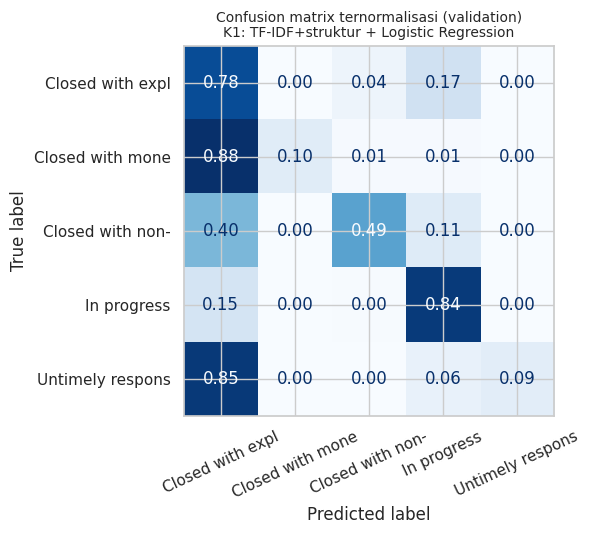

=== TEMUAN AWAL P4 (otomatis dari angka validation) ===
1. Model dengan F1-macro tertinggi: K1: TF-IDF+struktur + Logistic Regression (0.4866); selisih terhadap baseline +0.1624.
2. Metrik paling informatif: F1-macro, balanced accuracy, dan MCC. Akurasi hanya 0.570-0.714 antar model, sedangkan F1-macro berkisar 0.324-0.487 dan menunjukkan perbedaan kemampuan pada kelas kecil.
3. Efek fitur terstruktur (K1 vs baseline, model sama): F1-macro +0.1624, akurasi +0.1398.
4. Kelas minoritas 'Untimely response': recall baseline 0.000 vs K1: TF-IDF+struktur + Logistic Regression 0.090.
5. Biaya komputasi: tercepat K2: TF-IDF+struktur + Multinomial NB (4.9s), terlambat K3: TF-IDF+struktur + Linear SVM (34.8s).
Catatan: pemilihan akhir TIDAK memakai angka ini saja; model dipilih berdasarkan cross-validation di P5.


In [ ]:
# [CELL 19] Confusion matrix model terbaik (validation) & interpretasi otomatis P4
cand = df_results[df_results["Model"] != "Dummy (kelas mayoritas)"].set_index("Model")
best_val = cand["F1 (macro)"].idxmax()
fig, ax = plt.subplots(figsize=(7, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, preds[best_val], labels=LABELS, normalize="true"), display_labels=[str(l)[:16] for l in LABELS]).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=25, values_format=".2f")
ax.set_title(f"Confusion matrix ternormalisasi (validation)\n{best_val}", fontsize=10)
plt.tight_layout(); plt.show()

b = cand.loc[BASE_NAME]; bv = cand.loc[best_val]
minority = y_train.value_counts().idxmin()
def class_recall(name, c):
    return recall_score(y_val, preds[name], labels=[c], average="macro", zero_division=0)
fast = cand["Waktu latih (s)"].idxmin(); slow = cand["Waktu latih (s)"].idxmax()
print("=== TEMUAN AWAL P4 (otomatis dari angka validation) ===")
print(f"1. Model dengan F1-macro tertinggi: {best_val} ({bv['F1 (macro)']:.4f}); selisih terhadap baseline {bv['F1 (macro)'] - b['F1 (macro)']:+.4f}.")
print(f"2. Metrik paling informatif: F1-macro, balanced accuracy, dan MCC. Akurasi hanya {b['Accuracy']:.3f}-{cand['Accuracy'].max():.3f} antar model, "
      f"sedangkan F1-macro berkisar {cand['F1 (macro)'].min():.3f}-{cand['F1 (macro)'].max():.3f} dan menunjukkan perbedaan kemampuan pada kelas kecil.")
k1 = cand.loc["K1: TF-IDF+struktur + Logistic Regression"]
print(f"3. Efek fitur terstruktur (K1 vs baseline, model sama): F1-macro {k1['F1 (macro)'] - b['F1 (macro)']:+.4f}, akurasi {k1['Accuracy'] - b['Accuracy']:+.4f}.")
print(f"4. Kelas minoritas '{minority}': recall baseline {class_recall(BASE_NAME, minority):.3f} vs {best_val} {class_recall(best_val, minority):.3f}.")
print(f"5. Biaya komputasi: tercepat {fast} ({cand.loc[fast, 'Waktu latih (s)']:.1f}s), terlambat {slow} ({cand.loc[slow, 'Waktu latih (s)']:.1f}s).")
print("Catatan: pemilihan akhir TIDAK memakai angka ini saja; model dipilih berdasarkan cross-validation di P5.")

# PERTEMUAN 5 — Audit Validasi, Kestabilan, Ensemble & Imbalance
**Checkpoint:** strategi validasi, skor tiap fold (mean ± std), ensemble, analisis imbalance, keputusan perbaikan berbasis bukti.

## 7. Strategi Validasi
* **Skema A (utama, realistis): Stratified K-Fold** pada data dev (train+val). Cocok karena pengaduan baru tetap bertipe kategori masalah yang sudah dikenal; proporsi kelas dijaga pada tiap fold.
* **Skema B (stress test): GroupKFold** dengan grup = teks jenis masalah. Mengukur generalisasi ke **kombinasi masalah yang belum pernah terlihat**. Skema ini lebih ketat dan bukan pengganti Skema A.
* Overlap teks antara train dan validation **bukan** bukti baris identik atau kebocoran; itu wajar karena banyak pengaduan berbeda memiliki jenis masalah yang sama. Pengukurannya ada di sel berikut.

In [ ]:
# [CELL 20] Sampel CV, fold, dan ukuran overlap (teks vs baris-fitur penuh)
X_cv, y_cv = stratified_sample(X_dev, y_dev, CV_SAMPLE_N)
n_splits = int(max(2, min(CV_FOLDS, y_cv.value_counts().min())))
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
print(f"Data CV: {len(X_cv):,} baris | Stratified {n_splits}-Fold (random_state={RANDOM_STATE})")
SCORING = {"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "acc": "accuracy"}

train_texts = set(X_train["text_clean"]); train_rows = set(map(tuple, X_train.itertuples(index=False, name=None)))
txt_overlap = X_val["text_clean"].isin(train_texts).mean() * 100
row_overlap = pd.Series([tuple(r) in train_rows for r in X_val.itertuples(index=False, name=None)]).mean() * 100
print(f"Baris validation yang teksnya pernah muncul di train        : {txt_overlap:.2f}%")
print(f"Baris validation yang SELURUH fiturnya identik dengan train : {row_overlap:.2f}%")
print("Interpretasi: overlap teks tinggi adalah sifat data (kategori masalah terbatas). Overlap baris-fitur penuh lebih kecil bila fitur kategorikal "
      "ditambahkan; baris identik berlabel berbeda adalah derau alami yang menjadi batas performa.")

Data CV: 60,000 baris | Stratified 5-Fold (random_state=42)
Baris validation yang teksnya pernah muncul di train        : 99.86%
Baris validation yang SELURUH fiturnya identik dengan train : 86.32%
Interpretasi: overlap teks tinggi adalah sifat data (kategori masalah terbatas). Overlap baris-fitur penuh lebih kecil bila fitur kategorikal ditambahkan; baris identik berlabel berbeda adalah derau alami yang menjadi batas performa.


CV selesai: Baseline: TF-IDF(teks) + Logistic Regression (25.0s)
CV selesai: K1: TF-IDF+struktur + Logistic Regression (40.7s)
CV selesai: K2: TF-IDF+struktur + Multinomial NB (7.6s)
CV selesai: K3: TF-IDF+struktur + Linear SVM (25.6s)
CV selesai: K4: TF-IDF+struktur + Random Forest (35.3s)

--- SKOR TIAP FOLD ---


Model,Baseline: TF-IDF(teks) + Logistic Regression,K1: TF-IDF+struktur + Logistic Regression,K2: TF-IDF+struktur + Multinomial NB,K3: TF-IDF+struktur + Linear SVM,K4: TF-IDF+struktur + Random Forest
Fold,,,,,
1,0.3186,0.4595,0.4309,0.4458,0.4241
2,0.3178,0.4435,0.4334,0.4299,0.4137
3,0.3220,0.4776,0.4261,0.4589,0.4209
4,0.3170,0.4384,0.4397,0.4568,0.4227
5,0.3431,0.4464,0.4433,0.4568,0.4310



--- RINGKASAN: MEAN & STD ---


F1 macro         Balanced Acc         Accuracy        
                                                 mean     std         mean     std     mean     std
Model                                                                                              
Baseline: TF-IDF(teks) + Logistic Regression   0.3237  0.0110       0.3551  0.0090   0.5724  0.0025
K1: TF-IDF+struktur + Logistic Regression      0.4531  0.0158       0.4417  0.0095   0.7054  0.0044
K2: TF-IDF+struktur + Multinomial NB           0.4347  0.0069       0.6022  0.0184   0.5988  0.0035
K3: TF-IDF+struktur + Linear SVM               0.4497  0.0121       0.4383  0.0074   0.7060  0.0047
K4: TF-IDF+struktur + Random Forest            0.4225  0.0063       0.4300  0.0041   0.7050  0.0041

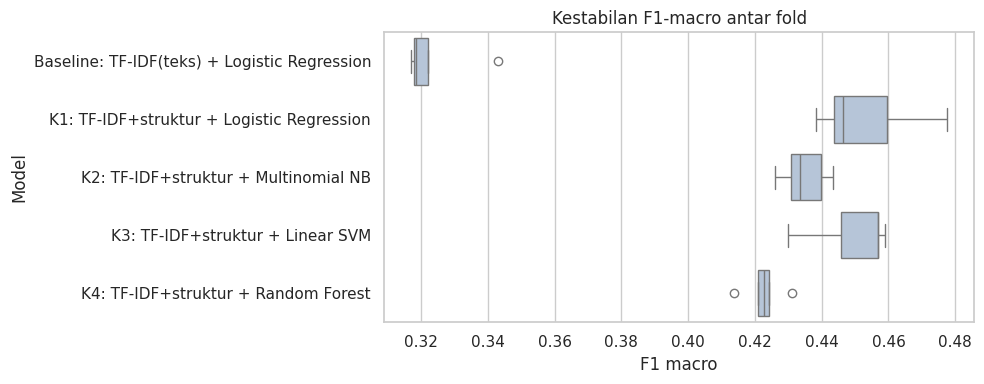

In [ ]:
# [CELL 21] Cross-validation semua model: skor tiap fold, mean, std
cv_scores = {}
for name, pipe in make_models().items():
    t0 = time.time()
    cv_scores[name] = cross_validate(clone(pipe), X_cv, y_cv, cv=skf, scoring=SCORING, n_jobs=1)
    print(f"CV selesai: {name} ({time.time()-t0:.1f}s)")

def fold_table(cvd):
    rows = []
    for name, cr in cvd.items():
        for i in range(len(cr["test_f1_macro"])):
            rows.append({"Model": name, "Fold": i + 1, "F1 macro": cr["test_f1_macro"][i], "Balanced Acc": cr["test_bal_acc"][i], "Accuracy": cr["test_acc"][i]})
    return pd.DataFrame(rows)

df_folds = fold_table(cv_scores)
print("\n--- SKOR TIAP FOLD ---")
display(df_folds.pivot(index="Fold", columns="Model", values="F1 macro").round(4))
df_cv = df_folds.groupby("Model")[["F1 macro", "Balanced Acc", "Accuracy"]].agg(["mean", "std"]).round(4)
print("\n--- RINGKASAN: MEAN & STD ---")
display(df_cv)
plt.figure(figsize=(10, 4)); sns.boxplot(data=df_folds, y="Model", x="F1 macro", color="lightsteelblue"); plt.title("Kestabilan F1-macro antar fold"); plt.tight_layout(); plt.show()

In [ ]:
# [CELL 22] Ensemble (Voting) + uji perbedaan terhadap baseline
def lr_pipe(): return Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE))])
def nb_pipe(): return Pipeline([("prep", make_prep()), ("clf", MultinomialNB())])
def svm_pipe(): return Pipeline([("prep", make_prep()), ("clf", LinearSVC(C=0.5, random_state=RANDOM_STATE))])

ensembles = {
    "E1: Voting hard (LR+NB+SVM)": VotingClassifier([("lr", lr_pipe()), ("nb", nb_pipe()), ("svm", svm_pipe())], voting="hard"),
    "E2: Voting soft (LR+NB)": VotingClassifier([("lr", lr_pipe()), ("nb", nb_pipe())], voting="soft"),
}
for name, est in ensembles.items():
    t0 = time.time()
    cv_scores[name] = cross_validate(est, X_cv, y_cv, cv=skf, scoring=SCORING, n_jobs=1)
    print(f"CV selesai: {name} ({time.time()-t0:.1f}s)")

base_f1 = np.asarray(cv_scores[BASE_NAME]["test_f1_macro"])
cmp_rows = []
for name, cr in cv_scores.items():
    f1s = np.asarray(cr["test_f1_macro"]); d = f1s - base_f1
    if name == BASE_NAME:
        p = np.nan
    else:
        p = stats.ttest_rel(f1s, base_f1).pvalue if np.std(d) > 0 else np.nan
    cmp_rows.append({"Model": name, "F1 macro (mean)": f1s.mean(), "F1 macro (std)": f1s.std(ddof=1), "Selisih vs baseline": d.mean(),
                     "p-value (paired t)": p, "Peningkatan signifikan?": ("ya" if (name != BASE_NAME and d.mean() > 0.005 and p == p and p < 0.05) else ("-" if name == BASE_NAME else "tidak"))})
df_compare = pd.DataFrame(cmp_rows).sort_values("F1 macro (mean)", ascending=False).reset_index(drop=True)
display(df_compare.round(4))
print("Catatan: fold CV tidak sepenuhnya independen, jadi p-value bersifat indikatif. Kriteria 'signifikan': selisih > 0,005 dan p < 0,05.")
BEST_CV = df_compare.iloc[0]["Model"]
print("Model terbaik berdasarkan CV (F1-macro mean):", BEST_CV)

CV selesai: E1: Voting hard (LR+NB+SVM) (74.6s)
CV selesai: E2: Voting soft (LR+NB) (47.5s)


,Model,F1 macro (mean),F1 macro (std),Selisih vs baseline,p-value (paired t),Peningkatan signifikan?
0,E2: Voting soft (LR+NB),0.4954,0.0196,0.1716,0.0000,ya
1,E1: Voting hard (LR+NB+SVM),0.4617,0.0119,0.1380,0.0000,ya
2,K1: TF-IDF+struktur + Logistic Regression,0.4531,0.0158,0.1294,0.0001,ya
3,K3: TF-IDF+struktur + Linear SVM,0.4497,0.0121,0.1259,0.0000,ya
4,K2: TF-IDF+struktur + Multinomial NB,0.4347,0.0069,0.1110,0.0000,ya
5,K4: TF-IDF+struktur + Random Forest,0.4225,0.0063,0.0988,0.0000,ya
6,Baseline: TF-IDF(teks) + Logistic Regression,0.3237,0.0110,0.0000,NaN,-


Catatan: fold CV tidak sepenuhnya independen, jadi p-value bersifat indikatif. Kriteria 'signifikan': selisih > 0,005 dan p < 0,05.
Model terbaik berdasarkan CV (F1-macro mean): E2: Voting soft (LR+NB)


## 8. Analisis Imbalance
Membandingkan strategi penanganan pada Logistic Regression + fitur terstruktur: tanpa bobot, `balanced`, dan `sqrt-balanced` (bobot lebih lembut). Metrik: F1-macro, balanced accuracy, dan recall kelas paling kecil.

In [ ]:
# [CELL 23] Persentase kelas, confusion matrix, dan perbandingan strategi imbalance (CV, data dev saja)
dist_tr = (y_cv.value_counts(normalize=True) * 100).round(3).to_frame("persen (data CV)")
dist_tr["jumlah"] = y_cv.value_counts()
display(dist_tr)

cnt = y_cv.value_counts()
cw_sqrt = ((len(y_cv) / (len(cnt) * cnt)) ** 0.5).to_dict()
minority_cv = cnt.idxmin()
scoring_imb = {"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "acc": "accuracy",
               "rec_min": make_scorer(lambda a, b: recall_score(a, b, labels=[minority_cv], average="macro", zero_division=0))}
strategies = {"tanpa bobot": None, "balanced": "balanced", "sqrt-balanced": cw_sqrt}
imb_rows = []
for sname, cw in strategies.items():
    pipe = Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=300, class_weight=cw, random_state=RANDOM_STATE))])
    cr = cross_validate(pipe, X_cv, y_cv, cv=skf, scoring=scoring_imb, n_jobs=1)
    imb_rows.append({"Strategi": sname, "F1 macro (mean)": cr["test_f1_macro"].mean(), "F1 macro (std)": cr["test_f1_macro"].std(ddof=1),
                     "Balanced Acc": cr["test_bal_acc"].mean(), "Accuracy": cr["test_acc"].mean(), f"Recall '{minority_cv}'": cr["test_rec_min"].mean()})
df_imb = pd.DataFrame(imb_rows).round(4)
display(df_imb)
BEST_STRATEGY = df_imb.sort_values("F1 macro (mean)", ascending=False).iloc[0]["Strategi"]
BEST_CW = strategies[BEST_STRATEGY]
print("Strategi imbalance terpilih (F1-macro CV tertinggi):", BEST_STRATEGY)

,persen (data CV),jumlah
target,,
Closed with explanation,45.923,27554
Closed with non-monetary relief,27.482,16489
In progress,25.535,15321
Closed with monetary relief,0.928,557
Untimely response,0.132,79


,Strategi,F1 macro (mean),F1 macro (std),Balanced Acc,Accuracy,Recall 'Untimely response'
0,tanpa bobot,0.4531,0.0158,0.4417,0.7054,0.0125
1,balanced,0.4591,0.0062,0.6993,0.6288,0.5933
2,sqrt-balanced,0.4994,0.0103,0.5907,0.6856,0.2517


Strategi imbalance terpilih (F1-macro CV tertinggi): sqrt-balanced


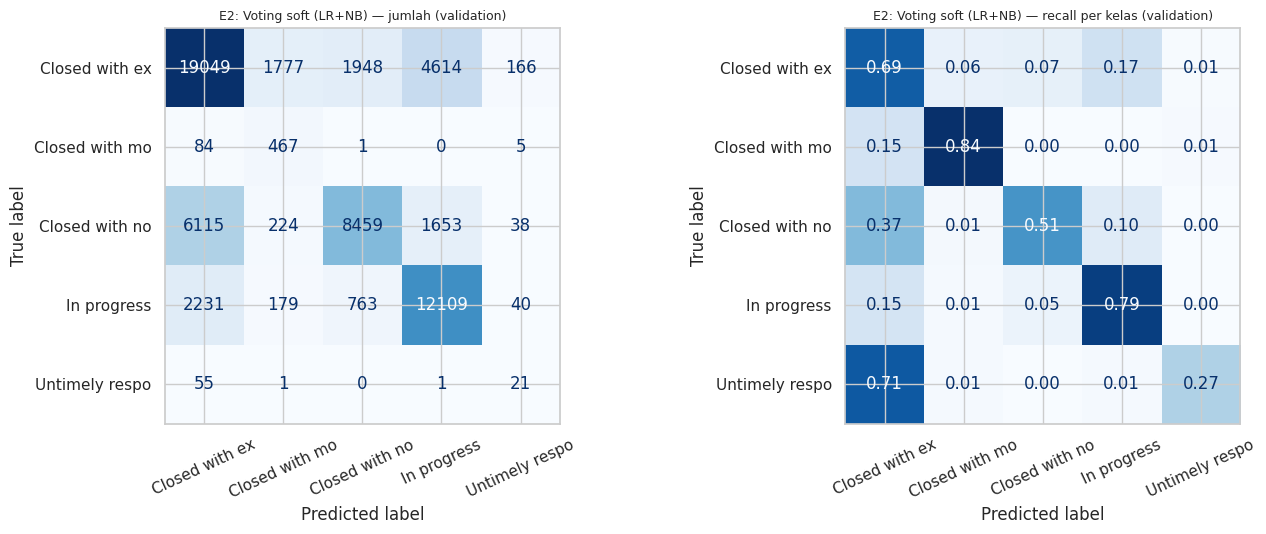

,Model,F1 macro Skema A (stratified),F1 macro Skema B (group),Std Skema B,Akurasi Skema B,Turun (B-A)
0,Baseline: TF-IDF(teks) + Logistic Regression,0.3237,0.1435,0.0300,0.4566,-0.1802
1,K1: TF-IDF+struktur + Logistic Regression,0.4531,0.3202,0.0929,0.5881,-0.1328
2,K2: TF-IDF+struktur + Multinomial NB,0.4347,0.2230,0.0697,0.3672,-0.2117


Skema B memaksa model menebak kombinasi jenis masalah yang belum pernah dilihat. Penurunan skor di sini = ketergantungan model pada kategori yang sudah dikenal.


In [ ]:
# [CELL 24] Confusion matrix model terbaik CV (validation) + Skema B (group CV) sebagai stress test
if BEST_CV in fitted:
    best_model_cv = fitted[BEST_CV]
else:
    best_model_cv = clone(ensembles[BEST_CV]).fit(X_train, y_train)
yp = best_model_cv.predict(X_val)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, norm, fmt, ttl in [(axes[0], None, "d", "jumlah"), (axes[1], "true", ".2f", "recall per kelas")]:
    ConfusionMatrixDisplay(confusion_matrix(y_val, yp, labels=LABELS, normalize=norm), display_labels=[str(l)[:14] for l in LABELS]).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=25, values_format=fmt)
    ax.set_title(f"{BEST_CV} — {ttl} (validation)", fontsize=9)
plt.tight_layout(); plt.show()

groups_cv = X_cv["text_clean"].values
gkf = GroupKFold(n_splits=int(min(5, len(set(groups_cv)))))
gscore = {}
for name in [BASE_NAME, "K1: TF-IDF+struktur + Logistic Regression", "K2: TF-IDF+struktur + Multinomial NB"]:
    gscore[name] = cross_validate(clone(make_models()[name]), X_cv, y_cv, cv=gkf, groups=groups_cv, scoring={"f1_macro": "f1_macro", "acc": "accuracy"}, n_jobs=1)
rows = []
for name, gc in gscore.items():
    rows.append({"Model": name, "F1 macro Skema A (stratified)": np.mean(cv_scores[name]["test_f1_macro"]),
                 "F1 macro Skema B (group)": gc["test_f1_macro"].mean(), "Std Skema B": gc["test_f1_macro"].std(ddof=1),
                 "Akurasi Skema B": gc["test_acc"].mean(), "Turun (B-A)": gc["test_f1_macro"].mean() - np.mean(cv_scores[name]["test_f1_macro"])})
df_group = pd.DataFrame(rows).round(4)
display(df_group)
print("Skema B memaksa model menebak kombinasi jenis masalah yang belum pernah dilihat. Penurunan skor di sini = ketergantungan model pada kategori yang sudah dikenal.")

In [ ]:
# [CELL 25] KEPUTUSAN PERBAIKAN berbasis bukti (otomatis; boleh Anda sunting)
cv_mean = {n: np.mean(c["test_f1_macro"]) for n, c in cv_scores.items()}
k1n = "K1: TF-IDF+struktur + Logistic Regression"
ens_gain = max(cv_mean["E1: Voting hard (LR+NB+SVM)"], cv_mean["E2: Voting soft (LR+NB)"]) - max(cv_mean[k] for k in cv_mean if k.startswith("K") or k == BASE_NAME)
sig = df_compare[df_compare["Peningkatan signifikan?"] == "ya"]["Model"].tolist()
print("=== KEPUTUSAN PERBAIKAN (P5) ===")
print(f"1. Validasi: Skema A (Stratified {n_splits}-Fold) dijadikan evaluasi utama; Skema B (group) dilaporkan sebagai stress test.")
print(f"2. Kestabilan: std F1-macro antar fold berkisar {df_compare['F1 macro (std)'].min():.4f}-{df_compare['F1 macro (std)'].max():.4f}.")
print(f"3. Fitur terstruktur: F1-macro CV baseline {cv_mean[BASE_NAME]:.4f} -> K1 {cv_mean[k1n]:.4f} ({cv_mean[k1n]-cv_mean[BASE_NAME]:+.4f}).")
print(f"4. Ensemble terhadap model tunggal terbaik: {ens_gain:+.4f} F1-macro. Model yang meningkat signifikan atas baseline: {sig if sig else 'tidak ada'}.")
print(f"5. Imbalance: strategi '{BEST_STRATEGY}' dipilih (F1-macro tertinggi). Trade-off: lihat kolom recall kelas minoritas dan akurasi pada tabel imbalance.")
print(f"6. Model untuk tuning P7: Logistic Regression + fitur terstruktur + class_weight '{BEST_STRATEGY}' (interpretabel, mendukung probabilitas dan bobot kelas). "
      f"Model terbaik CV saat ini: {BEST_CV}.")
print("7. Tahap selanjutnya: seleksi fitur, tuning, dan error analysis (P7); evaluasi akhir pada test hanya sekali di UTS.")

=== KEPUTUSAN PERBAIKAN (P5) ===
1. Validasi: Skema A (Stratified 5-Fold) dijadikan evaluasi utama; Skema B (group) dilaporkan sebagai stress test.
2. Kestabilan: std F1-macro antar fold berkisar 0.0063-0.0196.
3. Fitur terstruktur: F1-macro CV baseline 0.3237 -> K1 0.4531 (+0.1294).
4. Ensemble terhadap model tunggal terbaik: +0.0423 F1-macro. Model yang meningkat signifikan atas baseline: ['E2: Voting soft (LR+NB)', 'E1: Voting hard (LR+NB+SVM)', 'K1: TF-IDF+struktur + Logistic Regression', 'K3: TF-IDF+struktur + Linear SVM', 'K2: TF-IDF+struktur + Multinomial NB', 'K4: TF-IDF+struktur + Random Forest'].
5. Imbalance: strategi 'sqrt-balanced' dipilih (F1-macro tertinggi). Trade-off: lihat kolom recall kelas minoritas dan akurasi pada tabel imbalance.
6. Model untuk tuning P7: Logistic Regression + fitur terstruktur + class_weight 'sqrt-balanced' (interpretabel, mendukung probabilitas dan bobot kelas). Model terbaik CV saat ini: E2: Voting soft (LR+NB).
7. Tahap selanjutnya: seleksi f

# PERTEMUAN 6 — Unsupervised Learning & Dimensionality Reduction
**Checkpoint:** eksperimen representasi lanjutan / unsupervised text mining, evaluasi kestabilan clustering, karakteristik tiap kelompok.

Eksperimen ini mengelompokkan **jenis masalah unik** (teks) dari data dev memakai TF-IDF → TruncatedSVD (LSA) → KMeans (dibobot jumlah pengaduan), tanpa memakai label target. Label baru dipakai setelahnya untuk menilai apakah cluster selaras dengan hasil penanganan. Ini eksplorasi struktur, **bukan** pengganti klasifikasi.

Jenis masalah (teks) unik pada data dev: 1,140
TF-IDF: (1140, 1990) -> SVD 50 komponen; variansi dijelaskan: 0.5902


,k,Inertia,Silhouette,ARI antar seed (mean)
0,2,97638.2904,0.0312,1.0000
1,3,75800.7780,0.0389,1.0000
2,4,59672.4346,0.0384,1.0000
3,5,47797.9384,0.0429,1.0000
4,6,39978.2371,0.0446,1.0000
5,7,33029.6711,0.0430,0.9996
6,8,28900.1963,0.0709,0.9883
7,9,25511.9666,0.0879,0.9709
8,10,23205.7425,0.1166,0.9011
9,11,21018.3562,0.1554,0.7334


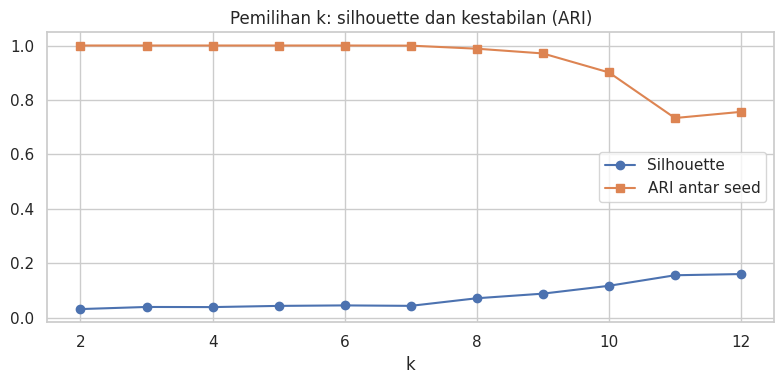

k terpilih (silhouette tertinggi): 12


In [ ]:
# [CELL 26] LSA + KMeans: pilih k lewat silhouette dan stabilitas antar seed
g6 = pd.DataFrame({"text_clean": X_dev["text_clean"].values}).groupby("text_clean").size().rename("n").reset_index()
n_u = len(g6)
print(f"Jenis masalah (teks) unik pada data dev: {n_u:,}")
RUN_P6 = n_u >= 12
if not RUN_P6:
    print("Teks unik terlalu sedikit untuk clustering; bagian ini dilewati.")
else:
    tfidf6 = TfidfVectorizer(ngram_range=(1, 2), max_features=3000, min_df=1, sublinear_tf=True)
    X6 = tfidf6.fit_transform(g6["text_clean"])
    n_comp = int(min(50, X6.shape[1] - 1, X6.shape[0] - 1))
    svd = TruncatedSVD(n_components=n_comp, random_state=RANDOM_STATE)
    Z = Normalizer(copy=False).fit_transform(svd.fit_transform(X6))
    print(f"TF-IDF: {X6.shape} -> SVD {n_comp} komponen; variansi dijelaskan: {svd.explained_variance_ratio_.sum():.4f}")
    w = g6["n"].values
    rows, labs = [], {}
    for k in range(2, min(13, n_u)):
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z, sample_weight=w)
        lab0 = km.labels_
        sil = silhouette_score(Z, lab0)
        aris = [adjusted_rand_score(lab0, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE + s).fit(Z, sample_weight=w).labels_) for s in range(1, 5)]
        rows.append({"k": k, "Inertia": km.inertia_, "Silhouette": sil, "ARI antar seed (mean)": float(np.mean(aris))})
        labs[k] = lab0
    df_k = pd.DataFrame(rows)
    display(df_k.round(4))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(df_k["k"], df_k["Silhouette"], marker="o", label="Silhouette")
    ax.plot(df_k["k"], df_k["ARI antar seed (mean)"], marker="s", label="ARI antar seed")
    ax.set_xlabel("k"); ax.set_title("Pemilihan k: silhouette dan kestabilan (ARI)"); ax.legend(); plt.tight_layout(); plt.show()
    best_k = int(df_k.sort_values("Silhouette", ascending=False).iloc[0]["k"])
    print("k terpilih (silhouette tertinggi):", best_k)

=== KARAKTERISTIK CLUSTER ===
Cluster 0: 68,432 pengaduan, 21 jenis masalah | kata kunci: credit reporting, reporting, reporting incorrect, information, else, someone else, belongs to, belongs
    contoh: credit reporting or other personal consumer reports credit reporting incorrect information on your report info
    contoh: credit reporting credit repair services or other personal consumer reports credit reporting incorrect informat
Cluster 1: 39,793 pengaduan, 25 jenis masalah | kata kunci: reporting, reporting improper, credit reporting, report improperly, used your, report reporting, company used, your report
    contoh: credit reporting credit repair services or other personal consumer reports credit reporting improper use of yo
    contoh: credit reporting or other personal consumer reports credit reporting improper use of your report reporting com
Cluster 2: 10,365 pengaduan, 533 jenis masalah | kata kunci: debt, mortgage, loan, to, debt collection, collection, or, conventional

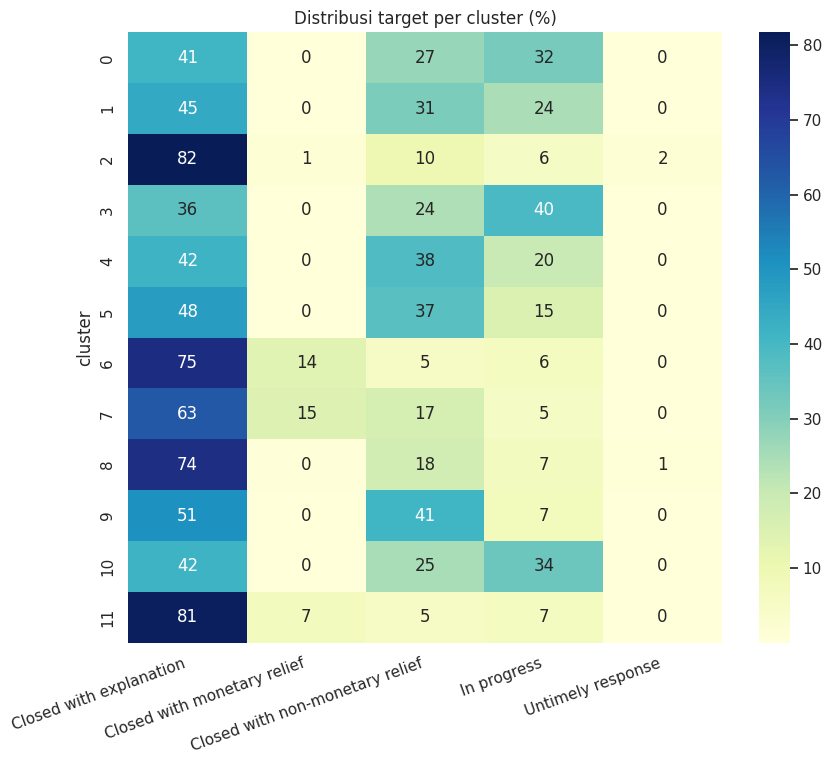

NMI antara cluster dan target: 0.0472 (0 = tidak ada hubungan; 1 = identik)


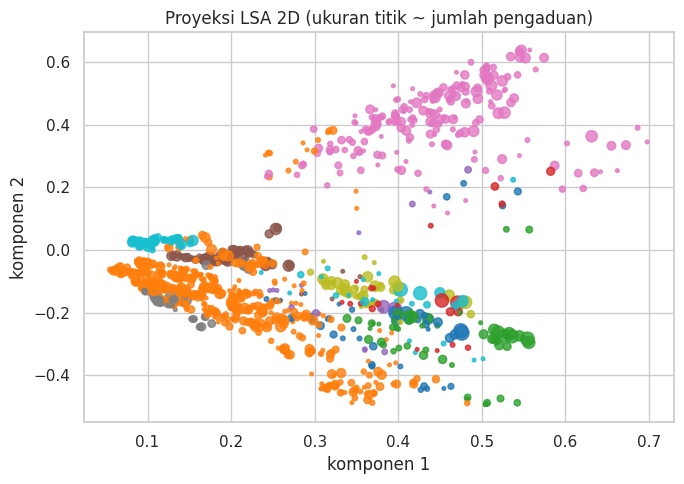


=== TOPIK NMF (pembanding topic modeling) ===
Topik 0: loan, loan or, title, title loan, loan title, payday loan, payday, personal loan
Topik 1: card, credit card, card or, credit, prepaid, prepaid card, or prepaid, card general
Topik 2: debt, collection, debt collection, to, not, threatened, collect, to collect
Topik 3: credit reporting, reporting, other personal, consumer, personal consumer, credit, personal, consumer reports
Topik 4: account, checking, savings, savings account, or savings, checking or, money, an account
Topik 5: incorrect, information, report, incorrect information, information on, your report, on, on your


In [ ]:
# [CELL 27] Karakteristik cluster, kaitan dengan target, visualisasi 2D, dan topik NMF
if RUN_P6:
    lab = labs[best_k]
    g6["cluster"] = lab
    terms6 = np.array(tfidf6.get_feature_names_out())
    print("=== KARAKTERISTIK CLUSTER ===")
    for cl in sorted(set(lab)):
        idx = np.where(lab == cl)[0]
        score = np.asarray(X6[idx].multiply(w[idx][:, None]).sum(axis=0)).ravel()
        top = terms6[score.argsort()[::-1][:8]]
        ex = g6.iloc[idx].sort_values("n", ascending=False).head(2)["text_clean"].tolist()
        print(f"Cluster {cl}: {int(w[idx].sum()):,} pengaduan, {len(idx)} jenis masalah | kata kunci: {', '.join(top)}")
        for e in ex: print("    contoh:", e[:110])
    text2cl = dict(zip(g6["text_clean"], g6["cluster"]))
    cl_dev = X_dev["text_clean"].map(text2cl)
    ct6 = pd.crosstab(cl_dev, y_dev, normalize="index") * 100
    plt.figure(figsize=(9, 3 + 0.4 * len(ct6)))
    sns.heatmap(ct6, annot=True, fmt=".0f", cmap="YlGnBu"); plt.title("Distribusi target per cluster (%)"); plt.xlabel(""); plt.ylabel("cluster")
    plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
    nmi = normalized_mutual_info_score(y_dev, cl_dev)
    print(f"NMI antara cluster dan target: {nmi:.4f} (0 = tidak ada hubungan; 1 = identik)")
    fig, ax = plt.subplots(figsize=(7, 5))
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=lab, s=np.log1p(w) * 10, cmap="tab10", alpha=0.8)
    ax.set_title("Proyeksi LSA 2D (ukuran titik ~ jumlah pengaduan)"); ax.set_xlabel("komponen 1"); ax.set_ylabel("komponen 2")
    plt.tight_layout(); plt.show()
    n_top = int(min(6, X6.shape[0] - 1, X6.shape[1] - 1))
    nmf = NMF(n_components=n_top, init="nndsvda", random_state=RANDOM_STATE, max_iter=400).fit(X6)
    print("\n=== TOPIK NMF (pembanding topic modeling) ===")
    for i, comp in enumerate(nmf.components_):
        print(f"Topik {i}: {', '.join(terms6[comp.argsort()[::-1][:8]])}")

In [ ]:
# [CELL 28] Interpretasi P6 (otomatis)
print("=== INTERPRETASI P6 ===")
if not RUN_P6:
    print("Clustering dilewati karena jenis masalah unik terlalu sedikit.")
else:
    r = df_k[df_k["k"] == best_k].iloc[0]
    qual = "lemah" if r["Silhouette"] < 0.25 else ("sedang" if r["Silhouette"] < 0.5 else "kuat")
    stab = "belum stabil" if r["ARI antar seed (mean)"] < 0.5 else "cukup stabil"
    print(f"1. k terpilih = {best_k}; silhouette {r['Silhouette']:.3f} (struktur cluster {qual}); ARI antar seed {r['ARI antar seed (mean)']:.3f} ({stab}).")
    print(f"2. Variansi yang dijelaskan {n_comp} komponen LSA: {svd.explained_variance_ratio_.sum():.3f}.")
    print(f"3. Kaitan cluster-target (NMI) = {nmi:.3f}: " + ("cluster jenis masalah belum menjelaskan hasil penanganan secara kuat." if nmi < 0.1 else "cluster jenis masalah cukup berhubungan dengan hasil penanganan."))
    print("4. Gunakan kata kunci dan contoh teks di atas untuk menamai tema cluster; jangan menyimpulkan tema mendalam tanpa memeriksa contohnya.")
    print("5. Representasi lanjutan (word embeddings) tidak dipakai karena proyek dibatasi pada classical ML; LSA dan NMF menjadi representasi laten.")

=== INTERPRETASI P6 ===
1. k terpilih = 12; silhouette 0.160 (struktur cluster lemah); ARI antar seed 0.756 (cukup stabil).
2. Variansi yang dijelaskan 50 komponen LSA: 0.590.
3. Kaitan cluster-target (NMI) = 0.047: cluster jenis masalah belum menjelaskan hasil penanganan secara kuat.
4. Gunakan kata kunci dan contoh teks di atas untuk menamai tema cluster; jangan menyimpulkan tema mendalam tanpa memeriksa contohnya.
5. Representasi lanjutan (word embeddings) tidak dipakai karena proyek dibatasi pada classical ML; LSA dan NMF menjadi representasi laten.


# PERTEMUAN 7 — Feature Selection, Error Analysis & Tuning
**Checkpoint:** seleksi fitur, error analysis pada kasus ekstrem/ambigu, hyperparameter tuning.
Seleksi dan tuning memakai **cross-validation pada subset stratified dari data dev**. Test tetap dikunci.

## 9. Seleksi Fitur

In [ ]:
# [CELL 29] SelectKBest(chi2): berapa banyak fitur yang dibutuhkan?
X_tune, y_tune = stratified_sample(X_dev, y_dev, TUNE_SAMPLE_N)
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
n_feat = len(make_prep().fit(X_tune).get_feature_names_out())
K_LIST = [k for k in [50, 100, 300, 1000, 3000] if k < n_feat] + ["all"]
print(f"Data tuning: {len(X_tune):,} baris | jumlah fitur total: {n_feat:,} | class_weight: {BEST_STRATEGY}")
rows = []
for k in K_LIST:
    pipe = Pipeline([("prep", make_prep()), ("select", SelectKBest(chi2, k=k)), ("clf", LogisticRegression(max_iter=300, class_weight=BEST_CW, random_state=RANDOM_STATE))])
    t0 = time.time()
    cr = cross_validate(pipe, X_tune, y_tune, cv=skf3, scoring={"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy"}, n_jobs=1)
    rows.append({"k fitur": k, "F1 macro (mean)": cr["test_f1_macro"].mean(), "F1 macro (std)": cr["test_f1_macro"].std(ddof=1),
                 "Balanced Acc": cr["test_bal_acc"].mean(), "Waktu (s)": time.time() - t0})
df_fs = pd.DataFrame(rows).round(4)
display(df_fs)

prep_fs = make_prep().fit(X_train)
fn = prep_fs.get_feature_names_out()
sk = SelectKBest(chi2, k=min(30, len(fn))).fit(prep_fs.transform(X_train), y_train)
print("\n30 fitur dengan skor chi2 tertinggi:")
print([n.replace("txt__", "").replace("cat__", "") for n in fn[sk.get_support()]])

Data tuning: 60,000 baris | jumlah fitur total: 626 | class_weight: sqrt-balanced


,k fitur,F1 macro (mean),F1 macro (std),Balanced Acc,Waktu (s)
0,50,0.4959,0.0185,0.5787,10.7149
1,100,0.4983,0.0130,0.5915,12.3091
2,300,0.5026,0.0055,0.6033,17.0334
3,all,0.4949,0.0134,0.5809,19.4595



30 fitur dengan skor chi2 tertinggi:
['card', 'charge', 'checking', 'fees', 'general', 'incorrect', 'information', 'interest', 'managing', 'prepaid', 'purchase', 'purpose', 'repair', 'resolving', 'savings', 'services', 'shown', 'statement', 'Company_BANK OF AMERICA, NATIONAL ASSOCIATION', 'Company_Bread Financial Holdings, Inc.', 'Company_CITIBANK, N.A.', 'Company_Conduent Incorporated', 'Company_EQUIFAX, INC.', 'Company_Experian Information Solutions Inc.', 'Company_MOHELA', 'Company_Servicer under contract with Federal Student Aid', 'Company_TRANSUNION INTERMEDIATE HOLDINGS, INC.', 'Company_WELLS FARGO & COMPANY', 'Company_infrequent_sklearn', 'Tags_Older American']


## 10. Hyperparameter Tuning

In [ ]:
# [CELL 30] RandomizedSearchCV (StratifiedKFold) — hanya pada subset dev
pipe_t = Pipeline([("prep", make_prep()), ("select", SelectPercentile(chi2)), ("clf", LogisticRegression(max_iter=300, random_state=RANDOM_STATE))])
param_dist = {"prep__txt__ngram_range": [(1, 1), (1, 2)], "prep__txt__max_features": [3000, 8000, 20000], "prep__txt__min_df": [1, 2, 5],
              "select__percentile": [40, 70, 100], "clf__C": loguniform(0.01, 30), "clf__class_weight": [None, "balanced", cw_sqrt]}
search = RandomizedSearchCV(pipe_t, param_dist, n_iter=N_ITER_TUNE, scoring="f1_macro", cv=skf3, n_jobs=1, refit=True,
                            random_state=RANDOM_STATE, error_score="raise")
t0 = time.time(); search.fit(X_tune, y_tune); print(f"Tuning selesai ({time.time()-t0:.1f}s) pada {len(X_tune):,} baris")
df_tune = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]].sort_values("rank_test_score")
display(df_tune.head(8).round(4))
print("Parameter terbaik (CV pada subset dev):", search.best_params_)
print(f"F1-macro CV: {search.best_score_:.4f}")
spread = df_tune["mean_test_score"].max() - df_tune["mean_test_score"].min()
print(f"Rentang skor antar kombinasi: {spread:.4f}")
if spread < 1e-4:
    print("[PERINGATAN] Semua kombinasi bernilai hampir sama: kemungkinan model hanya memprediksi kelas dominan atau fitur tidak informatif. "
          "Periksa distribusi prediksi, class_weight, dan fitur sebelum mempercayai hasil tuning.")

Tuning selesai (267.5s) pada 60,000 baris


,params,mean_test_score,std_test_score,rank_test_score
9,"{'clf__C': 0.06351054340728712, 'clf__class_weight': {'Closed with explanation': 0.6599306449336...",0.5012,0.0160,1
6,"{'clf__C': 0.049464081829378406, 'clf__class_weight': {'Closed with explanation': 0.659930644933...",0.4953,0.0061,2
2,"{'clf__C': 10.275417738969418, 'clf__class_weight': {'Closed with explanation': 0.65993064493363...",0.4921,0.0084,3
5,"{'clf__C': 0.01452988474687315, 'clf__class_weight': {'Closed with explanation': 0.6599306449336...",0.4798,0.0054,4
8,"{'clf__C': 22.783459357466153, 'clf__class_weight': 'balanced', 'prep__txt__max_features': 8000,...",0.4582,0.0061,5
1,"{'clf__C': 1.1893792844615376, 'clf__class_weight': 'balanced', 'prep__txt__max_features': 20000...",0.4575,0.0058,6
7,"{'clf__C': 2.3201272353300353, 'clf__class_weight': None, 'prep__txt__max_features': 20000, 'pre...",0.4529,0.0068,7
11,"{'clf__C': 0.0528491949013312, 'clf__class_weight': 'balanced', 'prep__txt__max_features': 3000,...",0.4451,0.0025,8


Parameter terbaik (CV pada subset dev): {'clf__C': np.float64(0.06351054340728712), 'clf__class_weight': {'Closed with explanation': 0.6599306449336347, 'Closed with non-monetary relief': 0.8530872752570694, 'In progress': 0.8850077355545455, 'Closed with monetary relief': 4.641549917575261, 'Untimely response': 12.324720450266415}, 'prep__txt__max_features': 20000, 'prep__txt__min_df': 1, 'prep__txt__ngram_range': (1, 2), 'select__percentile': 100}
F1-macro CV: 0.5012
Rentang skor antar kombinasi: 0.0834


In [ ]:
# [CELL 31] Model hasil tuning dilatih ulang pada TRAIN, dibandingkan di VALIDATION
tuned = clone(search.best_estimator_)
t0 = time.time(); tuned.fit(X_train, y_train); dur = time.time() - t0
TUNED_NAME = "Tuned: LR + fitur terstruktur + seleksi fitur"
r_t, yp_t = evaluate(tuned, X_val, y_val, TUNED_NAME, dur)
untuned = Pipeline([("prep", make_prep()), ("clf", LogisticRegression(max_iter=300, class_weight=BEST_CW, random_state=RANDOM_STATE))])
t0 = time.time(); untuned.fit(X_train, y_train); dur2 = time.time() - t0
r_u, yp_u = evaluate(untuned, X_val, y_val, "LR + struktur (strategi imbalance P5, tanpa tuning)", dur2)
tab = pd.DataFrame([results[0], results[1], r_u, r_t]).round(4)
display(tab)
tuned_gain = r_t["F1 (macro)"] - r_u["F1 (macro)"]
print(f"Selisih F1-macro tuned vs tanpa tuning (validation): {tuned_gain:+.4f}; vs baseline: {r_t['F1 (macro)'] - results[1]['F1 (macro)']:+.4f}")

,Model,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),MCC,PR-AUC (macro),Waktu latih (s)
0,Dummy (kelas mayoritas),0.4592,0.2000,0.0918,0.2000,0.1259,0.2890,0.0000,0.2000,NaN
1,Baseline: TF-IDF(teks) + Logistic Regression,0.5698,0.3539,0.3313,0.3539,0.3242,0.5368,0.3557,0.4031,17.0908
2,"LR + struktur (strategi imbalance P5, tanpa tuning)",0.6897,0.6795,0.5012,0.6795,0.5215,0.6897,0.5356,0.5527,36.1711
3,Tuned: LR + fitur terstruktur + seleksi fitur,0.6899,0.6665,0.5016,0.6665,0.5215,0.6896,0.5344,0.5466,32.7477


Selisih F1-macro tuned vs tanpa tuning (validation): +0.0001; vs baseline: +0.1973


## 11. Error Analysis

In [ ]:
# [CELL 32] Error analysis pada VALIDATION: per kelas, pasangan kesalahan, kasus ekstrem/ambigu
va = X_val.copy(); va["aktual"] = y_val.values; va["prediksi"] = yp_t; va["salah"] = va["aktual"] != va["prediksi"]
print(f"Jumlah salah: {int(va['salah'].sum()):,} dari {len(va):,} ({va['salah'].mean()*100:.1f}%)")
err_cls = va.groupby("aktual")["salah"].agg(["sum", "count", "mean"]).round(3); err_cls.columns = ["salah", "total", "error_rate"]
print("\nTingkat kesalahan per kelas aktual:"); display(err_cls.sort_values("error_rate", ascending=False))
print("Pasangan kesalahan tersering (aktual -> prediksi):")
display(va[va["salah"]].groupby(["aktual", "prediksi"]).size().sort_values(ascending=False).head(8).to_frame("jumlah"))

# Ambiguitas: seberapa seragam label pada kombinasi (teks + perusahaan) di data latih?
key_fn = lambda d: d["text_clean"] + "|" + (d["Company"] if "Company" in d.columns else "")
tr_key = key_fn(X_train); va_key = key_fn(X_val)
dist_key = pd.crosstab(tr_key, y_train, normalize="index")
purity = dist_key.max(axis=1)
va["purity"] = va_key.map(purity)
va["ambigu"] = va["purity"] < 0.6
amb = va.groupby("ambigu")["salah"].agg(["mean", "count"]).round(3)
amb.index = amb.index.map({True: "ambigu (label mayoritas < 60% pada kombinasi sama)", False: "tidak ambigu"})
print("\nError rate pada kombinasi ambigu vs tidak ambigu (data latih menentukan keambiguan):"); display(amb)
print(f"Kombinasi validation yang belum pernah muncul di train: {va['purity'].isna().mean()*100:.1f}%")

proba = tuned.predict_proba(X_val); cls_ = tuned.classes_
va["p_pred"] = proba.max(axis=1)
srt = np.sort(proba, axis=1); va["margin"] = srt[:, -1] - srt[:, -2]
cols_show = [c for c in ["text_clean", "Company"] if c in va.columns] + ["aktual", "prediksi", "p_pred"]
print("\nKasus salah dengan keyakinan tertinggi (prediksi keliru tapi 'yakin'):")
display(va[va["salah"]].sort_values("p_pred", ascending=False)[cols_show].head(8))
print("Kasus paling ambigu (selisih peluang dua kelas teratas terkecil):")
display(va.sort_values("margin")[cols_show + ["margin"]].head(8))
if "Company" in va.columns:
    print("Error rate per perusahaan (8 terbanyak):")
    display(va.groupby("Company")["salah"].agg(["sum", "count", "mean"]).round(3).sort_values("count", ascending=False).head(8))

Jumlah salah: 18,608 dari 60,000 (31.0%)

Tingkat kesalahan per kelas aktual:


,salah,total,error_rate
aktual,,,
Closed with non-monetary relief,7961,16489,0.483
Untimely response,35,78,0.449
Closed with explanation,8242,27554,0.299
Closed with monetary relief,163,557,0.293
In progress,2207,15322,0.144


Pasangan kesalahan tersering (aktual -> prediksi):


jumlah
aktual                          prediksi                               
Closed with non-monetary relief Closed with explanation            5885
Closed with explanation         In progress                        4840
                                Closed with non-monetary relief    2011
In progress                     Closed with explanation            1986
Closed with non-monetary relief In progress                        1926
Closed with explanation         Closed with monetary relief        1128
                                Untimely response                   263
Closed with monetary relief     Closed with explanation             156


Error rate pada kombinasi ambigu vs tidak ambigu (data latih menentukan keambiguan):


,mean,count
ambigu,,
tidak ambigu,0.259,46698
ambigu (label mayoritas < 60% pada kombinasi sama),0.491,13302


... (2 outputs left out)

Kasus paling ambigu (selisih peluang dua kelas teratas terkecil):


,text_clean,Company,aktual,prediksi,p_pred,margin
155469,credit card general purpose credit card or charge card other features terms or problems problem ...,CAPITAL ONE FINANCIAL CORPORATION,Closed with monetary relief,Closed with monetary relief,0.404925,0.000101
95619,credit card general purpose credit card or charge card other features terms or problems problem ...,CAPITAL ONE FINANCIAL CORPORATION,Closed with monetary relief,Closed with monetary relief,0.404925,0.000101
64144,debt collection medical debt took or threatened to take negative or legal action threatened to s...,"Simpson Law Firm, P.A.",Closed with explanation,Closed with explanation,0.466515,0.000159
133822,checking or savings account checking account managing an account deposits and withdrawals,FIFTH THIRD FINANCIAL CORPORATION,Closed with non-monetary relief,Closed with monetary relief,0.468274,0.000210
44729,debt collection auto debt false statements or representation attempted to collect wrong amount,Experian Information Solutions Inc.,Closed with explanation,Closed with explanation,0.403637,0.000252
117339,money transfer virtual currency or money service mobile or digital wallet fraud or scam,"Paypal Holdings, Inc",Closed with explanation,Closed with explanation,0.381997,0.000300
280506,credit card or prepaid card general purpose credit card or charge card closing your account comp...,"CITIBANK, N.A.",Closed with non-monetary relief,Closed with monetary relief,0.455440,0.000344
270827,credit reporting or other personal consumer reports other personal consumer report problem with ...,"Checkr, Inc",In progress,Closed with explanation,0.451908,0.000344


Error rate per perusahaan (8 terbanyak):


,sum,count,mean
Company,,,
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",4903,19068,0.257
Experian Information Solutions Inc.,4539,16560,0.274
"EQUIFAX, INC.",6154,14563,0.423
CAPITAL ONE FINANCIAL CORPORATION,167,520,0.321
WELLS FARGO & COMPANY,204,464,0.440
"BANK OF AMERICA, NATIONAL ASSOCIATION",249,456,0.546
JPMORGAN CHASE & CO.,154,433,0.356
"CITIBANK, N.A.",161,268,0.601


In [ ]:
# [CELL 33] Interpretabilitas: fitur paling berpengaruh per kelas (koefisien LR tuned) + ringkasan P7
prep_t, sel_t, clf_t = tuned.named_steps["prep"], tuned.named_steps["select"], tuned.named_steps["clf"]
names_t = np.array([n.replace("txt__", "").replace("cat__", "") for n in prep_t.get_feature_names_out()])[sel_t.get_support()]
print("=== FITUR PALING BERPENGARUH PER KELAS ===")
for i, c in enumerate(clf_t.classes_):
    top = clf_t.coef_[i].argsort()[::-1][:8]
    print(f"Kelas '{str(c)[:35]}': {', '.join(names_t[top])}")

print("\n=== RINGKASAN P7 ===")
print(f"1. Seleksi fitur: k terbaik pada CV = {df_fs.sort_values('F1 macro (mean)', ascending=False).iloc[0]['k fitur']} (F1-macro {df_fs['F1 macro (mean)'].max():.4f}).")
print(f"2. Tuning: F1-macro CV {search.best_score_:.4f}; pada validation {r_t['F1 (macro)']:.4f} ({tuned_gain:+.4f} dibanding tanpa tuning).")
worst_c = err_cls["error_rate"].idxmax()
print(f"3. Error analysis: error rate tertinggi pada '{worst_c}' ({err_cls.loc[worst_c, 'error_rate']:.3f}).")
if va["ambigu"].any():
    print(f"4. Ambiguitas: error rate pada kombinasi ambigu {va.loc[va['ambigu'],'salah'].mean():.3f} vs tidak ambigu {va.loc[~va['ambigu'],'salah'].mean():.3f}. "
          "Selama kombinasi fitur yang sama dapat berlabel berbeda, ada batas performa alami yang tidak bisa dilampaui oleh tuning.")
print("5. Keputusan: model final = pipeline hasil tuning (dibekukan SEBELUM test dibuka).")

=== FITUR PALING BERPENGARUH PER KELAS ===
Kelas 'Closed with explanation': services or, reporting credit, credit repair, repair, repair services, services, Company_Block, Inc., Company_I.C. System, Inc.
Kelas 'Closed with monetary relief': Company_Bread Financial Holdings, Inc., Company_CREDIT ACCEPTANCE CORPORATION, Company_BANK OF AMERICA, NATIONAL ASSOCIATION, fees, Company_CITIZENS FINANCIAL GROUP, INC., or prepaid, Company_CITIBANK, N.A., prepaid
Kelas 'Closed with non-monetary relief': Company_TRANSUNION INTERMEDIATE HOLDINGS, INC., services or, reporting credit, credit repair, repair services, repair, services, Company_EQUIFAX, INC.
Kelas 'In progress': reporting or, Company_Experian Information Solutions Inc., with company, Company_TRANSUNION INTERMEDIATE HOLDINGS, INC., Company_EQUIFAX, INC., Company_Kriya Capital, LLC, Company_Portfolio Recovery Associates, LLC, Company_NAVY FEDERAL CREDIT UNION
Kelas 'Untimely response': Company_Servicer under contract with Federal Student 

# UTS — Milestone 1: Penyelesaian Target Utama Proyek
**Checkpoint:** notebook utuh yang berjalan valid dari preprocessing, ekstraksi fitur, validasi kestabilan, hingga analisis temuan.

## 12. Evaluasi Akhir Satu Kali pada Test Set
Model terbaik sementara dan baseline **dilatih ulang pada data dev (train+val)** lalu dievaluasi **satu kali** pada test yang selama ini dikunci. Tidak ada pemilihan model setelah langkah ini.

--- HASIL AKHIR PADA TEST SET (dipakai sekali) ---


,Model,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),MCC,PR-AUC (macro),Waktu latih (s)
0,Dummy (kelas mayoritas),0.4592,0.2000,0.0918,0.2000,0.1259,0.2890,0.0000,0.2000,NaN
1,Baseline: TF-IDF(teks) + Logistic Regression,0.5690,0.3554,0.4455,0.3554,0.3277,0.5326,0.3534,0.4090,NaN
2,MODEL FINAL (tuned),0.6891,0.7013,0.5087,0.7013,0.5323,0.6881,0.5328,0.5765,46.2246



=== CLASSIFICATION REPORT MODEL FINAL (test) ===
                                 precision    recall  f1-score   support

        Closed with explanation       0.70      0.70      0.70     27554
    Closed with monetary relief       0.24      0.72      0.36       557
Closed with non-monetary relief       0.81      0.51      0.63     16489
                    In progress       0.66      0.86      0.74     15322
              Untimely response       0.14      0.72      0.23        78

                       accuracy                           0.69     60000
                      macro avg       0.51      0.70      0.53     60000
                   weighted avg       0.71      0.69      0.69     60000



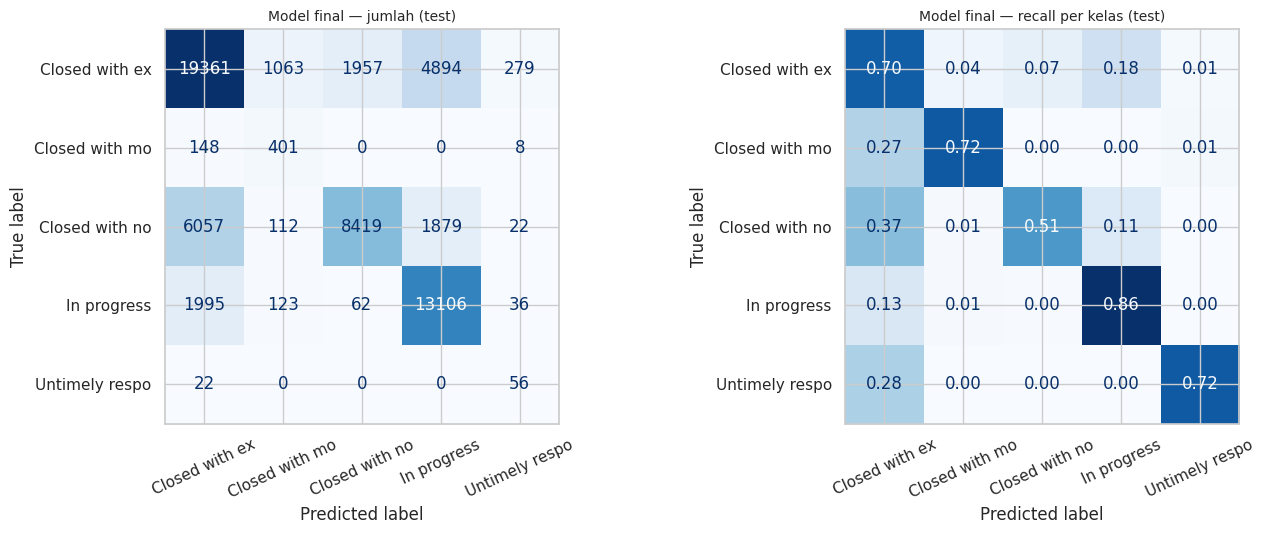

In [ ]:
# [CELL 34] Evaluasi akhir (test dibuka satu kali)
final_model = clone(search.best_estimator_)
t0 = time.time(); final_model.fit(X_dev, y_dev); dur_f = time.time() - t0
base_final = clone(make_models()[BASE_NAME]).fit(X_dev, y_dev)
dummy_final = DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev)
rows, preds_test = [], {}
for nm, m, dt in [("Dummy (kelas mayoritas)", dummy_final, np.nan), (BASE_NAME, base_final, np.nan), ("MODEL FINAL (tuned)", final_model, dur_f)]:
    r, yp_ = evaluate(m, X_test, y_test, nm, dt); rows.append(r); preds_test[nm] = yp_
df_final = pd.DataFrame(rows).round(4)
print("--- HASIL AKHIR PADA TEST SET (dipakai sekali) ---")
display(df_final)
print("\n=== CLASSIFICATION REPORT MODEL FINAL (test) ===")
print(classification_report(y_test, preds_test["MODEL FINAL (tuned)"], zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, norm, fmt, ttl in [(axes[0], None, "d", "jumlah"), (axes[1], "true", ".2f", "recall per kelas")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds_test["MODEL FINAL (tuned)"], labels=LABELS, normalize=norm), display_labels=[str(l)[:14] for l in LABELS]).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=25, values_format=fmt)
    ax.set_title(f"Model final — {ttl} (test)", fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
# [CELL 35] Sintesis otomatis, audit, dan checklist
ff = df_final.set_index("Model")
fin, bas, dum = ff.loc["MODEL FINAL (tuned)"], ff.loc[BASE_NAME], ff.loc["Dummy (kelas mayoritas)"]
print("=== SINTESIS HASIL ===")
print(f"1. Test: model final F1-macro {fin['F1 (macro)']:.4f}, balanced acc {fin['Balanced Acc']:.4f}, MCC {fin['MCC']:.4f}, akurasi {fin['Accuracy']:.4f}.")
print(f"2. Dibanding baseline (teks saja): F1-macro {fin['F1 (macro)'] - bas['F1 (macro)']:+.4f}, akurasi {fin['Accuracy'] - bas['Accuracy']:+.4f}. Dibanding dummy: F1-macro {fin['F1 (macro)'] - dum['F1 (macro)']:+.4f}.")
dv = fin['F1 (macro)'] - r_t['F1 (macro)']
print(f"3. Konsistensi: F1-macro validation {r_t['F1 (macro)']:.4f} vs test {fin['F1 (macro)']:.4f} (selisih {dv:+.4f}); "
      + ("selisih kecil: tidak ada tanda overfit ke validation." if abs(dv) <= 0.02 else "selisih cukup besar: periksa overfit ke validation atau perbedaan komposisi data."))
gB = df_group.set_index("Model")
print(f"4. Stress test Skema B (kombinasi masalah baru): F1-macro CV baseline {gB.iloc[0]['F1 macro Skema B (group)']:.4f}; K1 {gB.iloc[1]['F1 macro Skema B (group)']:.4f}.")
print("5. Batas performa: pengaduan dengan fitur identik dapat berlabel berbeda; ini menetapkan plafon alami pada skor (lihat analisis ambiguitas di P7).")
if TRUNCATED:
    print("6. KETERBATASAN DATA: file terpotong di batas Excel, sampel tidak acak; generalisasi ke populasi penuh CFPB belum terbukti.")
if TEXT_MODE == "structured":
    print("7. KETERBATASAN FITUR: tanpa kolom narasi, model hanya melihat jenis masalah dan atribut kategorikal.")

audit = pd.DataFrame([
    ("Audit pemotongan data (batas Excel)", "Ya", "terpotong" if TRUNCATED else "tidak terindikasi"),
    ("Kolom pasca-respons dikeluarkan dari fitur", "Ya", ", ".join(LEAKY_COLS)),
    ("Split dilakukan sebelum fit TF-IDF/OHE", "Ya", "Pipeline + ColumnTransformer"),
    ("Test set dikunci hingga evaluasi akhir", "Ya", "dibuka sekali di CELL 34"),
    ("Pemilihan model memakai validation/CV, bukan test", "Ya", "P4 validation; P5 dan P7 CV"),
    ("Validasi stratified + stress test group", "Ya", f"{n_splits}-fold A; GroupKFold B"),
    ("Kestabilan dilaporkan (skor tiap fold, mean, std)", "Ya", "CELL 21"),
    ("Imbalance dianalisis (metrik + strategi)", "Ya", BEST_STRATEGY),
    ("Seed tetap (reproducible)", "Ya", f"RANDOM_STATE={RANDOM_STATE}"),
    ("Sampel kerja", "Ya", f"{len(df_model):,} dari {len(df_all):,} baris"),
], columns=["Item audit", "Terpenuhi", "Keterangan"])
print("\n=== CHECKLIST AUDIT ===")
display(audit)

=== SINTESIS HASIL ===
1. Test: model final F1-macro 0.5323, balanced acc 0.7013, MCC 0.5328, akurasi 0.6891.
2. Dibanding baseline (teks saja): F1-macro +0.2046, akurasi +0.1201. Dibanding dummy: F1-macro +0.4064.
3. Konsistensi: F1-macro validation 0.5215 vs test 0.5323 (selisih +0.0108); selisih kecil: tidak ada tanda overfit ke validation.
4. Stress test Skema B (kombinasi masalah baru): F1-macro CV baseline 0.1435; K1 0.3202.
5. Batas performa: pengaduan dengan fitur identik dapat berlabel berbeda; ini menetapkan plafon alami pada skor (lihat analisis ambiguitas di P7).
6. KETERBATASAN DATA: file terpotong di batas Excel, sampel tidak acak; generalisasi ke populasi penuh CFPB belum terbukti.
7. KETERBATASAN FITUR: tanpa kolom narasi, model hanya melihat jenis masalah dan atribut kategorikal.

=== CHECKLIST AUDIT ===


,Item audit,Terpenuhi,Keterangan
0,Audit pemotongan data (batas Excel),Ya,terpotong
1,Kolom pasca-respons dikeluarkan dari fitur,Ya,"Timely response?, Company public response"
2,Split dilakukan sebelum fit TF-IDF/OHE,Ya,Pipeline + ColumnTransformer
3,Test set dikunci hingga evaluasi akhir,Ya,dibuka sekali di CELL 34
4,"Pemilihan model memakai validation/CV, bukan test",Ya,P4 validation; P5 dan P7 CV
5,Validasi stratified + stress test group,Ya,5-fold A; GroupKFold B
6,"Kestabilan dilaporkan (skor tiap fold, mean, std)",Ya,CELL 21
7,Imbalance dianalisis (metrik + strategi),Ya,sqrt-balanced
8,Seed tetap (reproducible),Ya,RANDOM_STATE=42
9,Sampel kerja,Ya,"300,000 dari 1,048,573 baris"


In [ ]:
# [CELL 36] Simpan hasil & informasi lingkungan
import joblib
df_results.to_csv(os.path.join(OUT_DIR, "p4_perbandingan_validation.csv"), index=False)
df_compare.to_csv(os.path.join(OUT_DIR, "p5_cv_perbandingan.csv"), index=False)
df_folds.to_csv(os.path.join(OUT_DIR, "p5_skor_tiap_fold.csv"), index=False)
df_imb.to_csv(os.path.join(OUT_DIR, "p5_imbalance.csv"), index=False)
df_group.to_csv(os.path.join(OUT_DIR, "p5_group_stress_test.csv"), index=False)
df_final.to_csv(os.path.join(OUT_DIR, "uts_hasil_test.csv"), index=False)
joblib.dump(final_model, os.path.join(OUT_DIR, "model_final.joblib"))
print("Tersimpan di:", os.path.abspath(OUT_DIR), "->", sorted(os.listdir(OUT_DIR)))
print({"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "RANDOM_STATE": RANDOM_STATE})

Tersimpan di: /content/outputs -> ['model_final.joblib', 'p4_perbandingan_validation.csv', 'p5_cv_perbandingan.csv', 'p5_group_stress_test.csv', 'p5_imbalance.csv', 'p5_skor_tiap_fold.csv', 'uts_hasil_test.csv']
{'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'RANDOM_STATE': 42}


## 13. Keterbatasan & Langkah Lanjut
* **Data:** bila file terpotong di batas Excel, unduh ulang CSV asli CFPB dan baca langsung dengan pandas; jalankan ulang notebook ini tanpa perubahan lain.
* **Fitur:** bila tersedia kolom narasi (`Consumer complaint narrative`), notebook otomatis memakainya (hanya untuk baris yang punya narasi). Ini sumber peningkatan terbesar yang paling mungkin.
* **Batas performa:** pengaduan dengan fitur identik dapat berlabel berbeda, sehingga ada plafon alami pada akurasi.
* **Kelas `In progress` dan `Untimely response`** adalah status proses, bukan hasil akhir. Pertimbangkan merumuskan ulang target (mis. hanya hasil akhir "Closed ...") bila tujuan bisnisnya memprediksi hasil penyelesaian.
* **Pasca-UTS:** stemming/lemmatization, embeddings, kalibrasi probabilitas, dan penyesuaian ambang keputusan per kelas.